# 🎯 Tarea 6 — Encoder estático, complejidad y variantes del Transformer para el WTAP

**Rediseñamos el modelo del módulo 2 para que el encoder se ejecute una sola vez por instancia, analizamos la complejidad de encoder y decoder, y comparamos la arquitectura base con dos variantes: sesgo inductivo con el criterio de MMR y un decoder con atención eficiente (ISAB).**

El Transformer con puntero del proyecto del módulo 2 (`Proyecto_WTAP_transformer.ipynb`) recibía en cada paso una secuencia de `1 + W·T` filas con 16 features, y la mayoría eran **dinámicas** (probabilidad de sobrevivir, ganancia de MMR, anticipación, …). Como esas features cambian tras cada asignación, su "encoder" se volvía a ejecutar en **cada decisión**. Aquí separamos las responsabilidades: el **encoder** solo ve la información estática de la instancia ($V_j$ y $p_{ij}$) y corre una vez; el **decoder** integra el estado en cada paso.

| Sección | Contenido | Punto de la tarea |
|---|---|---|
| 2 | Problema, entorno, MMR y experto ILS (código del módulo 2) | — |
| 3 | Diagnóstico del módulo 2: qué features eran dinámicas y cuánto costaba re-codificar | 1 |
| 4 | Datos: trayectorias del experto para entrenar con *teacher forcing* | 4 |
| 5 | Arquitectura base rediseñada y variantes A (sesgo inductivo MMR) y B (decoder con ISAB) | 1 y 3 |
| 6 | Complejidad temporal del encoder y del decoder: análisis y medición | 2 |
| 7 | Entrenamiento de los 3 modelos con la misma configuración | 4 |
| 8 | Convergencia | 5 |
| 9 | Evaluación con instancias de distintos tamaños (gap vs el experto ILS) | 6 |
| 10 | Discusión y conclusiones | — |

> ⏱️ La ejecución completa (`RAPIDO = False`, 3 semillas por modelo) tomó 68 min en CPU con 4 hilos: 63 min de entrenamiento (42 de ellos de la variante B) y unos 5 min de datos, mediciones y evaluación. Con `RAPIDO = True` (menos datos, 1 semilla) corre en pocos minutos. Si hay GPU se usa para entrenar; las mediciones de tiempo de la sección 6 se hacen siempre en CPU con 1 hilo.

## 1. Instalación y librerías

Usamos la librería del curso [`eda`](https://github.com/rilianx/eda) para el `GreedyAgent` y el `SingleAgentSolver`, igual que en las tareas anteriores.

In [1]:
!test -d eda || git clone -q https://github.com/rilianx/eda.git

In [2]:
import os, json, time, copy, random, itertools, math, statistics
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from copy import deepcopy

from eda.agents import SingleAgentSolver, GreedyAgent
from eda.utils import handle_multiple_states

RAPIDO = False                         # True: 1 500 instancias, 1 semilla y 15 épocas (para probar el notebook)
N_SEEDS = 1 if RAPIDO else 3           # semillas de inicialización por modelo (estabilidad de la convergencia)
N_WEAPONS, N_TARGETS = 10, 8           # tamaño de ENTRENAMIENTO (el mismo de las Tareas 4-5 y del proyecto)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_THREADS = torch.get_num_threads()
print("Dispositivo:", device, "| hilos de CPU:", N_THREADS)

os.makedirs("figuras_t6", exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(f"figuras_t6/{nombre}.png", dpi=160, bbox_inches="tight")

MODELOS = {"Base": "base", "A · sesgo MMR": "A", "B · ISAB": "B"}      # nombre en tablas -> variante
COLORES = {"Base": "tab:blue", "A · sesgo MMR": "tab:purple", "B · ISAB": "tab:green",
           "MMR": "tab:orange", "Aleatorio": "tab:gray", "Módulo 2": "#9db4d6"}

Dispositivo: cpu | hilos de CPU: 4


## 2. El problema, el entorno, MMR y el experto (código del módulo 2)

$W$ armas y $T$ objetivos; el objetivo $j$ vale $V_j$ y el arma $i$ lo destruye con probabilidad $p_{ij}$. Cada arma se asigna a un objetivo y se minimiza el valor esperado que sobrevive:

$$\min_x \; Z = \sum_{j=1}^{T} V_j \prod_{i=1}^{W} (1 - p_{ij})^{x_{ij}}, \qquad q_j = \prod_i (1-p_{ij})^{x_{ij}} \;\text{(prob. de que } j \text{ sobreviva)}$$

Instancias de la literatura (Ahuja et al., 2007): $V_j \sim U\{25,\dots,100\}$, $p_{ij} \sim U(0{,}6;\,0{,}9)$. La acción constructiva es un **par** (arma libre $i$ → objetivo $j$); con $k$ armas libres hay $k\cdot T$ acciones. Las funciones de esta sección se copian **sin cambios** del notebook del proyecto: entorno, **MMR** (en cada paso el par con mayor ganancia marginal $g_{ij} = V_j\,q_j\,p_{ij}$), el **experto ILS** (MMR + búsqueda local `reassign`/`swap` + perturbación; en las tareas anteriores alcanzó el óptimo exacto en todas las instancias verificadas de 5×4 y 10×8) y la **descomposición** de su solución en W decisiones (en cada paso, el par del experto con mayor ganancia marginal). Del entorno dejamos solo las acciones constructivas, que son las que usa el agente.

In [3]:
class WTAP_Instance:
    def __init__(self, values, probs):
        self.values = np.asarray(values, dtype=float)   # V_j,  forma (T,)
        self.probs  = np.asarray(probs,  dtype=float)   # p_ij, forma (W, T)
        self.n_weapons, self.n_targets = self.probs.shape

    @staticmethod
    def random(n_weapons=N_WEAPONS, n_targets=N_TARGETS, rng=np.random):
        values = rng.randint(25, 101, size=n_targets).astype(float)
        probs  = rng.uniform(0.6, 0.9, size=(n_weapons, n_targets))
        return WTAP_Instance(values, probs)


class WTAP_State:
    # assignment[i] = objetivo asignado al arma i (-1 si el arma i aún está libre)
    def __init__(self, inst_info, assignment=None):
        self.inst_info = inst_info
        self.assignment = list(assignment) if assignment is not None else [-1] * inst_info.n_weapons
        self.update_cost()

    def update_cost(self):
        P = self.inst_info.probs
        self.q = np.ones(self.inst_info.n_targets)
        for i, j in enumerate(self.assignment):
            if j >= 0:
                self.q[j] *= 1 - P[i, j]
        self.cost = float(self.inst_info.values @ self.q)
        return self.cost

    @property
    def free_weapons(self):
        return [i for i, j in enumerate(self.assignment) if j < 0]

    @property
    def is_complete(self):
        return all(j >= 0 for j in self.assignment)

    def __deepcopy__(self, memo):
        return type(self)(self.inst_info, list(self.assignment))


class WTAP_Environment:
    @staticmethod
    def gen_actions(state, type, shuffle=False):
        if type != "constructive":
            raise NotImplementedError(f"Tipo de acción '{type}' no implementado")
        actions = [("constructive", (i, j)) for i in state.free_weapons for j in range(state.inst_info.n_targets)]
        if shuffle:
            random.shuffle(actions)
        for action in actions:
            yield action

    @staticmethod
    def state_transition(state, action):
        P, V = state.inst_info.probs, state.inst_info.values
        kind, (i, j) = action
        if kind != "constructive" or state.assignment[i] >= 0:
            raise NotImplementedError(f"Movimiento '{action}' no válido")
        state.assignment[i] = j
        state.q[j] *= 1 - P[i, j]
        state.cost = float(V @ state.q)
        return state


def cost_of(inst, assignment):
    P = inst.probs
    q = np.ones(inst.n_targets)
    for i, j in enumerate(assignment):
        if j >= 0:
            q[j] *= 1 - P[i, j]
    return float(inst.values @ q)

env = WTAP_Environment


@handle_multiple_states
def evalConstructiveActions(state, env):
    # MMR: ganancia marginal V_j * q_j * p_ij de cada par (arma libre i, objetivo j)
    V, P = state.inst_info.values, state.inst_info.probs
    return [(a, V[a[1][1]] * state.q[a[1][1]] * P[a[1][0], a[1][1]]) for a in env.gen_actions(state, "constructive")]


def mmr(inst):
    V, P = inst.values, inst.probs
    q = np.ones(inst.n_targets)
    assignment = [-1] * inst.n_weapons
    free = list(range(inst.n_weapons))
    while free:
        gains = (V * q)[None, :] * P[free]
        r, j = np.unravel_index(np.argmax(gains), gains.shape)
        i = free.pop(r)
        assignment[i] = int(j)
        q[j] *= 1 - P[i, j]
    return assignment


def q_of(P, a, T):
    q = np.ones(T)
    np.multiply.at(q, a, 1 - P[np.arange(len(a)), a])
    return q


def local_search(V, P, a, q):
    # best improvement con vecindarios reassign + swap (deltas vectorizados)
    W, T = P.shape
    idx = np.arange(W)
    while True:
        pa = P[idx, a]
        removal = V[a] * q[a] * pa / (1 - pa)
        delta_re = removal[:, None] - (V * q)[None, :] * P
        delta_re[idx, a] = np.inf
        term = (V[a] * q[a])[:, None] * ((1 - P[:, a].T) / (1 - pa)[:, None] - 1)
        delta_sw = term + term.T
        delta_sw[a[:, None] == a[None, :]] = np.inf
        best_re, best_sw = delta_re.min(), delta_sw.min()
        if min(best_re, best_sw) > -1e-9:
            return a, q
        if best_re <= best_sw:
            i, j = np.unravel_index(np.argmin(delta_re), delta_re.shape)
            q[a[i]] /= 1 - P[i, a[i]]; q[j] *= 1 - P[i, j]; a[i] = j
        else:
            i, k = np.unravel_index(np.argmin(delta_sw), delta_sw.shape)
            ai, ak = a[i], a[k]
            q[ai] *= (1 - P[k, ai]) / (1 - P[i, ai])
            q[ak] *= (1 - P[i, ak]) / (1 - P[k, ak])
            a[i], a[k] = ak, ai


def ils(inst, n_iter=100, k_perturb=3, rng=None):
    # experto: MMR + búsqueda local + perturbación de 3 armas; acepta si mejora (o con prob. 5 %)
    rng = rng or np.random.default_rng()
    V, P = inst.values, inst.probs
    W, T = P.shape
    a = np.array(mmr(inst))
    a, q = local_search(V, P, a, q_of(P, a, T))
    cur_cost = V @ q
    best_a, best_cost = a.copy(), cur_cost
    for _ in range(n_iter):
        b = a.copy()
        ws = rng.choice(W, size=k_perturb, replace=False)
        b[ws] = rng.integers(0, T, size=k_perturb)
        b, qb = local_search(V, P, b, q_of(P, b, T))
        cb = V @ qb
        if cb < cur_cost - 1e-12 or rng.random() < 0.05:
            a, cur_cost = b, cb
        if cb < best_cost - 1e-12:
            best_a, best_cost = b.copy(), cb
    return [int(x) for x in best_a], cost_of(inst, best_a)


def decompose(inst, expert_assignment):
    # (estado, acciones posibles, acción escogida); orden: par del experto con mayor ganancia marginal
    V, P, a = inst.values, inst.probs, expert_assignment
    state = WTAP_State(inst)
    while not state.is_complete:
        free = state.free_weapons
        gains = [V[a[i]] * state.q[a[i]] * P[i, a[i]] for i in free]
        i = free[int(np.argmax(gains))]
        chosen = ("constructive", (i, a[i]))
        yield deepcopy(state), list(env.gen_actions(state, "constructive")), chosen
        env.state_transition(state, chosen)


def solve_instances(n_weapons, n_targets, n_instances, seed):
    # instancias aleatorias resueltas por el experto (mismas semillas que en las tareas anteriores)
    rng, rng_ils = np.random.RandomState(seed), np.random.default_rng(seed)
    solved = []
    for _ in range(n_instances):
        inst = WTAP_Instance.random(n_weapons, n_targets, rng=rng)
        expert_assignment, expert_cost = ils(inst, rng=rng_ils)
        solved.append((inst, expert_assignment, expert_cost))
    return solved


def gap(costs, expert_costs):
    return 100 * (np.asarray(costs) / np.asarray(expert_costs) - 1)


def make_random_eval(seed):
    # constructivo aleatorio: puntajes uniformes, el GreedyAgent elige un par válido al azar
    rng = np.random.default_rng(seed)
    @handle_multiple_states
    def evalRandomActions(state, env):
        return [(action, rng.random()) for action in env.gen_actions(state, "constructive")]
    return evalRandomActions


def agent_costs(eval_actions, instances):
    # rollout con el GreedyAgent de eda para muchas instancias a la vez
    finals, *_ = SingleAgentSolver(env, GreedyAgent(eval_actions)).multistate_solve([WTAP_State(i) for i in instances])
    assert all(s.is_complete for s in finals)
    return np.array([s.cost for s in finals])


mmr_agent = SingleAgentSolver(env, GreedyAgent(evalConstructiveActions))
rng = np.random.RandomState(5)
for _ in range(20):
    inst = WTAP_Instance.random(rng=rng)
    assert mmr_agent.solve(WTAP_State(inst))[0].assignment == mmr(inst)
print("✔ GreedyAgent(evalConstructiveActions) reproduce exactamente a MMR")

✔ GreedyAgent(evalConstructiveActions) reproduce exactamente a MMR


## 3. Punto 1 — Diagnóstico de la arquitectura del módulo 2

En el módulo 2 la entrada era una matriz `(1 + W·T) × 16`: una fila global y una fila por par (arma, objetivo). El "encoder" (2 capas de self-attention sobre esas filas) y el puntero se ejecutaban **juntos en cada paso**, porque la entrada se recalculaba con `state2vec(estado)` después de cada asignación. Copiamos `state2vec` y `WTAP_Attention` del proyecto (solo para este diagnóstico y para medir tiempos en la sección 6) y comprobamos empíricamente qué columnas cambian a lo largo de una construcción.

In [4]:
# ---- código del módulo 2 (sin cambios), solo para el diagnóstico y las mediciones de tiempo ----
FEATURES = ["p_ij", "valor", "p_vs_mejor", "es_global", "no_disponible", "asignado",
            "q_sobrevive", "valor_en_juego", "ganancia", "es_mmr", "armas_en_obj", "ventaja",
            "arrepentimiento", "mmr_completa", "q_final_mmr", "frac_restantes"]
VEC_LEN, COL_GLOBAL, COL_MASK = len(FEATURES), 3, 4


def mmr_completion(V, P, q, free):
    q = q.copy(); free = list(free); target = {}
    while free:
        gains = (V * q)[None, :] * P[free]
        r, j = np.unravel_index(np.argmax(gains), gains.shape)
        i = free.pop(r); q[j] *= 1 - P[i, j]; target[i] = int(j)
    return target, q


def state2vec(state):
    inst = state.inst_info
    V, P = inst.values, inst.probs
    W, T = P.shape
    a = np.asarray(state.assignment)
    q, vmax = state.q, V.max()
    free = a < 0
    fw, done = np.flatnonzero(free), np.flatnonzero(~free)
    F = np.zeros((W, T, VEC_LEN))
    F[:, :, 0] = P
    F[:, :, 1] = V[None, :] / vmax
    F[:, :, 2] = P - P.max(1, keepdims=True)
    F[:, :, 4] = (~free)[:, None]
    F[done, a[done], 5] = 1
    F[:, :, 6] = q[None, :]
    F[:, :, 7] = (V * q / vmax)[None, :]
    F[:, :, 10] = (np.bincount(a[done], minlength=T) / W)[None, :]
    F[:, :, 15] = len(fw) / W
    if len(fw):
        gain = (V * q)[None, :] * P[fw]
        gmax = gain.max()
        F[fw, :, 8] = gain / gmax
        r, j = np.unravel_index(np.argmax(gain), gain.shape)
        F[fw[r], j, 9] = 1
        F[fw, :, 11] = P[fw] - P[fw].mean(0, keepdims=True)
        if len(fw) > 1:
            srt = np.sort(gain, axis=0)
            other = np.where(gain >= srt[-1][None, :], srt[-2][None, :], srt[-1][None, :])
        else:
            other = np.zeros_like(gain)
        F[fw, :, 12] = (gain - other) / gmax
        target, q_mmr = mmr_completion(V, P, q, fw)
        for i, j in target.items():
            F[i, j, 13] = 1
        F[:, :, 14] = q_mmr[None, :]
    g = np.zeros(VEC_LEN)
    g[COL_GLOBAL], g[COL_MASK] = 1, 1
    g[7] = V @ q / V.sum()
    g[15] = len(fw) / W
    return np.concatenate([g[None, :], F.reshape(W * T, VEC_LEN)]).astype(np.float32)


class EncoderBlock(nn.Module):
    def __init__(self, d, dropout):
        super().__init__()
        self.d = d
        self.Wq = nn.Linear(d, d, bias=False); self.Wk = nn.Linear(d, d, bias=False); self.Wv = nn.Linear(d, d, bias=False)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.ReLU(), nn.Linear(2 * d, d))
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)

    def forward(self, H):
        Q, K, V = self.Wq(H), self.Wk(H), self.Wv(H)
        A = torch.softmax(Q @ K.transpose(1, 2) / self.d ** 0.5, dim=-1)     # (batch, n, n): cuadrático en n
        H = self.norm1(H + self.drop(A @ V))
        return self.norm2(H + self.drop(self.ff(H)))


class WTAP_Attention(nn.Module):
    def __init__(self, vec_len=VEC_LEN, d=64, n_layers=2, dropout=0.0):
        super().__init__()
        self.d = d
        self.embed = nn.Linear(vec_len, d)
        self.encoder = nn.ModuleList([EncoderBlock(d, dropout) for _ in range(n_layers)])
        self.Wc = nn.Linear(2 * d, d)
        self.Wq_ptr = nn.Linear(d, d, bias=False); self.Wk_ptr = nn.Linear(d, d, bias=False)

    def forward(self, x, return_probabilities=False):
        if x.dim() == 2:
            x = x.unsqueeze(0)
        H = self.embed(x)
        for block in self.encoder:
            H = block(H)
        h_global = H[x[:, :, COL_GLOBAL] == 1]
        disp = (x[:, :, COL_MASK] == 0).float().unsqueeze(-1)
        h_disp = (H * disp).sum(1) / disp.sum(1).clamp(min=1)
        q = self.Wc(torch.cat([h_global, h_disp], dim=-1))
        u = (self.Wk_ptr(H) @ self.Wq_ptr(q).unsqueeze(-1)).squeeze(-1) / self.d ** 0.5
        u = u.masked_fill(x[:, :, COL_MASK] == 1, -1e9)
        return torch.softmax(u, dim=-1) if return_probabilities else u


# ---- diagnóstico: ¿qué columnas de state2vec cambian durante una construcción? ----
np.random.seed(7)
inst_demo = WTAP_Instance.random()                      # misma instancia de ejemplo de las tareas anteriores
sol_demo, cost_demo = ils(inst_demo, rng=np.random.default_rng(0))
X_steps = np.stack([state2vec(st) for st, _, _ in decompose(inst_demo, sol_demo)])   # (W pasos, 1 + W·T, 16)
dinamica = np.abs(X_steps - X_steps[:1]).max(axis=(0, 1)) > 1e-9
print(f"{'#':>2}  {'feature':<16} tipo")
for k, f in enumerate(FEATURES):
    print(f"{k:>2}  {f:<16} {'DINÁMICA (cambia con el estado)' if dinamica[k] else 'estática'}")
print(f"\n{dinamica.sum()} de las {VEC_LEN} features cambian entre pasos -> el encoder del módulo 2 se recalculaba "
      f"en cada una de las W = {N_WEAPONS} decisiones.")
DIAGNOSTICO = {"n_features": VEC_LEN, "n_dinamicas": int(dinamica.sum()),
               "dinamicas": [f for f, d in zip(FEATURES, dinamica) if d],
               "estaticas": [f for f, d in zip(FEATURES, dinamica) if not d]}

 #  feature          tipo
 0  p_ij             estática
 1  valor            estática
 2  p_vs_mejor       estática
 3  es_global        estática
 4  no_disponible    DINÁMICA (cambia con el estado)
 5  asignado         DINÁMICA (cambia con el estado)
 6  q_sobrevive      DINÁMICA (cambia con el estado)
 7  valor_en_juego   DINÁMICA (cambia con el estado)
 8  ganancia         DINÁMICA (cambia con el estado)
 9  es_mmr           DINÁMICA (cambia con el estado)
10  armas_en_obj     DINÁMICA (cambia con el estado)
11  ventaja          DINÁMICA (cambia con el estado)
12  arrepentimiento  DINÁMICA (cambia con el estado)
13  mmr_completa     DINÁMICA (cambia con el estado)
14  q_final_mmr      DINÁMICA (cambia con el estado)
15  frac_restantes   DINÁMICA (cambia con el estado)

12 de las 16 features cambian entre pasos -> el encoder del módulo 2 se recalculaba en cada una de las W = 10 decisiones.


**Conclusión del diagnóstico.** Solo la información de la instancia ($p_{ij}$, $V_j$ y lo que se deriva de ellos) es estática. Todo lo demás (máscara, $q_j$, ganancia, arrepentimiento, anticipación con MMR, …) depende de la solución parcial, así que el bloque de self-attention del módulo 2 **no era un encoder en el sentido de la tarea**: era parte del cómputo de cada decisión. Eso tiene dos costos (sección 6): la self-attention sobre $1+W\cdot T$ filas es $O((WT)^2)$ **por paso**, y `state2vec` agrega $O(W^2 T)$ por paso porque `mmr_completa` simula MMR hasta el final.

### Rediseño (arquitectura base)
- **Encoder (estático, 1 vez por instancia).** Las armas **no tienen información propia** (solo su fila de $p$), así que cada arma parte de un **token aprendible** compartido; cada objetivo parte de un embedding de $V_j/\max V$. La matriz $p_{ij}$ entra como **aristas** de un grafo bipartito, mediante **atención cruzada armas ↔ objetivos que inyecta $p_{ij}$** en el puntaje y en el mensaje (idea de EGAT vista en el curso y de MatNet, Kwon et al. 2021).
- **Decoder (cada paso).** Recibe el **estado**: armas libres (máscara) y, por objetivo, $q_j$ y el valor en juego $V_j q_j$. Arma un contexto, hace un *glimpse* (Kool et al., 2019) y puntúa cada par con un **puntero aditivo** que también ve la arista $p_{ij}$.
- Se eliminan las features heurísticas por paso (ganancia, arrepentimiento, `es_mmr`, `mmr_completa`, `q_final_mmr`): el modelo debe aprenderlas de $V$, $p$ y $q$. La ganancia de MMR vuelve solo en la **variante A**, como sesgo inductivo explícito.

## 4. Datos: trayectorias del experto (*teacher forcing*)

Usamos **las mismas instancias y el mismo experto** que en las tareas anteriores: 6 000 instancias 10×8 de entrenamiento (semilla 0), 300 de validación (semilla 1) y 50 de prueba (semilla 2024). Lo que cambia es el formato. Como el encoder ya no depende del estado, una muestra es ahora **una instancia completa con sus W decisiones**: el encoder se ejecuta una vez por instancia y el decoder se evalúa en los W estados de la trayectoria del experto en paralelo (*teacher forcing*).

| Tensor | Forma | Contenido |
|---|---|---|
| `P` | (N, W, T) | probabilidades $p_{ij}$ (estático, al encoder) |
| `V` | (N, T) | valores $V_j$ (estático, al encoder) |
| `FREE` | (N, W pasos, W) | armas libres antes de cada decisión (estado, al decoder) |
| `Q` | (N, W pasos, T) | $q_j$ antes de cada decisión (estado, al decoder) |
| `Y` | (N, W pasos) | par escogido por el experto, codificado como $i\cdot T + j$ |

In [5]:
def trajectories(solved):
    # convierte instancias resueltas (todas del mismo tamaño) en tensores de teacher forcing
    N = len(solved)
    W, T = solved[0][0].probs.shape
    P = np.zeros((N, W, T), np.float32); V = np.zeros((N, T), np.float32)
    FREE = np.zeros((N, W, W), bool); Q = np.zeros((N, W, T), np.float32); Y = np.zeros((N, W), np.int64)
    for k, (inst, expert_assignment, _) in enumerate(solved):
        P[k], V[k] = inst.probs, inst.values
        for t, (state, actions, chosen) in enumerate(decompose(inst, expert_assignment)):
            FREE[k, t] = np.asarray(state.assignment) < 0
            Q[k, t] = state.q
            i, j = chosen[1]
            Y[k, t] = i * T + j
    return {"P": torch.tensor(P), "V": torch.tensor(V), "FREE": torch.tensor(FREE),
            "Q": torch.tensor(Q), "Y": torch.tensor(Y)}


N_TRAIN = 1500 if RAPIDO else 6000
t0 = time.time()
train_solved = solve_instances(N_WEAPONS, N_TARGETS, N_TRAIN, seed=0)
val_solved   = solve_instances(N_WEAPONS, N_TARGETS, 300, seed=1)
test_solved  = solve_instances(N_WEAPONS, N_TARGETS, 50, seed=2024)
D_train, D_val, D_test = trajectories(train_solved), trajectories(val_solved), trajectories(test_solved)
print(f"Datos generados en {time.time() - t0:.0f} s")
for name, D in [("train", D_train), ("val", D_val), ("test", D_test)]:
    print(f"{name:>5}: " + " | ".join(f"{k} {tuple(v.shape)}" for k, v in D.items()) + f"  -> {D['Y'].numel():,} decisiones")

val_insts = [inst for inst, _, _ in val_solved[:100]]          # 100 instancias para el gap de validación por época
val_expert = np.array([c for _, _, c in val_solved[:100]])
test_insts = [inst for inst, _, _ in test_solved]
test_expert = np.array([c for _, _, c in test_solved])
print(f"Costo medio del experto en las 50 de prueba: {test_expert.mean():.3f} (el mismo de las Tareas 4-5 y el proyecto: 46.263)")

# sanity checks: la etiqueta siempre es un par de un arma libre y q es consistente con las decisiones previas
for D in (D_train, D_val, D_test):
    N, W, T = D["P"].shape
    i_lab = D["Y"] // T
    assert D["FREE"].gather(2, i_lab.unsqueeze(-1)).all()                                  # arma de la etiqueta libre
    assert (D["FREE"].sum(-1) == (W - torch.arange(W)).unsqueeze(0)).all()                  # W - t armas libres
    q = torch.ones(N, T)
    for t in range(W):
        assert torch.allclose(D["Q"][:, t], q, atol=1e-5)
        i, j = D["Y"][:, t] // T, D["Y"][:, t] % T
        q[torch.arange(N), j] *= 1 - D["P"][torch.arange(N), i, j]
print("✔ Etiquetas válidas y estados q_j consistentes con las decisiones del experto")

Datos generados en 60 s
train: P (6000, 10, 8) | V (6000, 8) | FREE (6000, 10, 10) | Q (6000, 10, 8) | Y (6000, 10)  -> 60,000 decisiones
  val: P (300, 10, 8) | V (300, 8) | FREE (300, 10, 10) | Q (300, 10, 8) | Y (300, 10)  -> 3,000 decisiones
 test: P (50, 10, 8) | V (50, 8) | FREE (50, 10, 10) | Q (50, 10, 8) | Y (50, 10)  -> 500 decisiones
Costo medio del experto en las 50 de prueba: 46.263 (el mismo de las Tareas 4-5 y el proyecto: 46.263)
✔ Etiquetas válidas y estados q_j consistentes con las decisiones del experto


## 5. Arquitecturas (puntos 1 y 3)

Los tres modelos comparten la configuración: $d = 64$, 4 cabezas, 2 capas de encoder, feed-forward $64\to128\to64$, LayerNorm después de cada residual (como en el módulo 2) y recorte de logits $C\tanh(\cdot)$ con $C = 10$ (Kool et al., 2019). Escalamos $p_{ij}$ a $\tilde p_{ij} = (p_{ij} - 0{,}75)/0{,}15 \in [-1, 1]$.

### 5.1 Arquitectura base rediseñada

**Encoder estático** (1 vez por instancia). $h^w_i = \mathbf{w}_{\text{token}}$ (aprendible, igual para todas las armas) y $h^t_j = W_v\,(V_j/\max V) + b_v$. Cada una de las 2 capas aplica atención cruzada en las dos direcciones, en paralelo, con la arista en el puntaje y en el mensaje:

$$s^{(h)}_{ij} = \frac{(W_Q h^w_i)^{(h)}\cdot (W_K h^t_j)^{(h)}}{\sqrt{d_h}} + \beta^{(h)}\,\tilde p_{ij}, \qquad m_i = W_O\Big[\sum_j \operatorname{softmax}_j\!\big(s^{(h)}_{ij}\big)\,\big((W_V h^t_j)^{(h)} + w_e^{(h)}\tilde p_{ij} + b_e^{(h)}\big)\Big]_{h=1..4}$$

seguido de $h^w \leftarrow \mathrm{LN}(h^w + m)$ y $h^w \leftarrow \mathrm{LN}(h^w + \mathrm{FF}(h^w))$; lo mismo para los objetivos atendiendo a las armas (con $\tilde p_{ji}$). Costo por capa: $O(W\,T\,d + (W+T)\,d^2)$, **lineal en el tamaño de la matriz $p$**. Además el encoder deja precalculadas las partes del puntero que no dependen del estado ($W_A h^w_i$ y $W_E \tilde p_{ij}$).

**Decoder** (cada paso $t$). Estado por objetivo $s_j(t) = [\,q_j,\; v_j q_j,\; \ln(v_j q_j)\,]$ con $v_j = V_j/\max V$:

1. **Objetivos con su estado:** $h_j(t) = \mathrm{LN}\big(h^t_j + \mathrm{MLP}(s_j(t))\big)$.
2. **Contexto:** $c = W_c\,[\,\overline{h^w}_{\text{libres}} \,;\, \overline{h(t)} \,;\, k/W \,;\, \textstyle\sum_j v_j q_j / \sum_j v_j\,]$ ($k$ = armas libres).
3. **Glimpse** (MHA de 4 cabezas): $c$ atiende a las armas libres y a los objetivos; residual + LN + FF.
4. **Puntero por pares (aditivo, con arista):** $u_{ij} = C\tanh\!\Big(\big(W_r c\big)^{\top}\,\mathrm{ReLU}\big(W_A h^w_i + W_B h_j(t) + W_E \tilde p_{ij}\big)/\sqrt d\Big)$, con $u_{ij} = -10^9$ si el arma $i$ ya fue usada; softmax sobre los $W\cdot T$ pares.

Costo por paso: $O(W\,T\,d + (W+T)\,d^2)$, lineal en el número de acciones $n = W\cdot T$ (cualquier puntero que entregue un logit por acción necesita al menos $\Omega(n)$).

| | Módulo 2 | Base rediseñada |
|---|---|---|
| Tokens | $1 + W\cdot T$ filas (fila global + pares) con 16 features | $W$ armas (token aprendible) + $T$ objetivos ($V_j$) + matriz $p_{ij}$ como aristas |
| Encoder | self-attention entre las $1+WT$ filas, 1 cabeza, **se ejecuta en cada paso** | atención cruzada armas↔objetivos con aristas, 4 cabezas, **1 vez por instancia** |
| Información dinámica | dentro de las features de entrada | solo en el decoder: máscara de armas, $q_j$, valor en juego, progreso |
| Features heurísticas | ganancia, arrepentimiento, `es_mmr`, `mmr_completa`, `q_final_mmr` | ninguna (la ganancia vuelve como sesgo en la variante A) |
| Contexto | $[h_{\text{global}} ; \bar h_{\text{disp}}]$ | $[\bar h^w_{\text{libres}} ; \overline{h(t)} ; \text{progreso}]$ + glimpse MHA |
| Puntero | $q\cdot h_r/\sqrt d$ sobre filas | aditivo sobre pares con la arista $p_{ij}$ y recorte $C\tanh$ |
| Entrenamiento | estados independientes | *teacher forcing*: 1 encoder + W pasos por instancia |

In [6]:
D_MODEL, N_HEADS, N_LAYERS, D_FF, CLIP, N_INDUCING = 64, 4, 2, 128, 10.0, 16
NEG = -1e9


def p_scaled(P):
    # p_ij ~ U(0.6, 0.9) -> [-1, 1]  (escala fija: no depende de la instancia ni de su tamaño)
    return (P - 0.75) / 0.15


def feed_forward(d, d_ff):
    return nn.Sequential(nn.Linear(d, d_ff), nn.ReLU(), nn.Linear(d_ff, d))


class EdgeCrossAttention(nn.Module):
    # MHA de un conjunto (queries) sobre el otro (keys/values) con la arista p_ij inyectada
    # en el puntaje (peso aprendido por cabeza) y en el mensaje (vector aprendido), al estilo EGAT
    def __init__(self, d, h):
        super().__init__()
        self.h, self.dh = h, d // h
        self.Wq = nn.Linear(d, d, bias=False)
        self.Wk = nn.Linear(d, d, bias=False)
        self.Wv = nn.Linear(d, d, bias=False)
        self.Wo = nn.Linear(d, d)
        self.edge_score = nn.Parameter(torch.zeros(h))       # beta^(h): peso de la arista en el puntaje
        self.edge_msg = nn.Linear(1, d)                      # w_e, b_e: arista -> vector del mensaje

    def forward(self, X, Y, E, bias=None):
        # X: (B, Nx, d) queries · Y: (B, Ny, d) keys/values · E: (B, Nx, Ny) aristas escaladas
        B, Nx, d = X.shape
        Ny = Y.shape[1]
        q = self.Wq(X).view(B, Nx, self.h, self.dh).transpose(1, 2)            # (B, h, Nx, dh)
        k = self.Wk(Y).view(B, Ny, self.h, self.dh).transpose(1, 2)
        v = self.Wv(Y).view(B, Ny, self.h, self.dh).transpose(1, 2)
        s = q @ k.transpose(-1, -2) / self.dh ** 0.5                           # (B, h, Nx, Ny)
        s = s + self.edge_score.view(1, -1, 1, 1) * E.unsqueeze(1)             # + arista en el puntaje
        if bias is not None:
            s = s + bias                                                       # sesgo inductivo (variante A)
        att = torch.softmax(s, dim=-1)
        out = att @ v                                                          # mensajes de los nodos
        e_mean = (att * E.unsqueeze(1)).sum(-1, keepdim=True)                  # (B, h, Nx, 1)
        w = self.edge_msg.weight.view(1, self.h, 1, self.dh)
        b = self.edge_msg.bias.view(1, self.h, 1, self.dh)
        out = out + e_mean * w + b                                             # + mensajes de las aristas
        return self.Wo(out.transpose(1, 2).reshape(B, Nx, d))


class BipartiteLayer(nn.Module):
    # una capa del encoder: armas <- objetivos y objetivos <- armas, en paralelo
    def __init__(self, d, h, d_ff):
        super().__init__()
        self.att_w, self.att_t = EdgeCrossAttention(d, h), EdgeCrossAttention(d, h)
        self.ff_w, self.ff_t = feed_forward(d, d_ff), feed_forward(d, d_ff)
        self.n_w1, self.n_w2, self.n_t1, self.n_t2 = (nn.LayerNorm(d) for _ in range(4))

    def forward(self, Hw, Ht, E, bias_w=None, bias_t=None):
        mw = self.att_w(Hw, Ht, E, bias_w)                       # cada arma mira a los T objetivos
        mt = self.att_t(Ht, Hw, E.transpose(1, 2), bias_t)       # cada objetivo mira a las W armas
        Hw = self.n_w1(Hw + mw); Hw = self.n_w2(Hw + self.ff_w(Hw))
        Ht = self.n_t1(Ht + mt); Ht = self.n_t2(Ht + self.ff_t(Ht))
        return Hw, Ht


class StaticEncoder(nn.Module):
    # solo información estática: V_j y p_ij. Arma = token aprendible; objetivo = Linear(V_j / max V)
    def __init__(self, d, h, n_layers, d_ff):
        super().__init__()
        self.weapon_token = nn.Parameter(torch.randn(d) * 0.5)
        self.target_embed = nn.Linear(1, d)
        self.layers = nn.ModuleList([BipartiteLayer(d, h, d_ff) for _ in range(n_layers)])

    def forward(self, P, V, attn_bias=None):
        B, W, T = P.shape
        E = p_scaled(P)
        Hw = self.weapon_token.expand(B, W, -1)
        Ht = self.target_embed((V / V.amax(1, keepdim=True)).unsqueeze(-1))
        for l, layer in enumerate(self.layers):
            bw, bt = attn_bias(l) if attn_bias is not None else (None, None)
            Hw, Ht = layer(Hw, Ht, E, bw, bt)
        return Hw, Ht


def target_state(V, q):
    # estado dinámico de cada objetivo: [q_j, v_j q_j, ln(v_j q_j)] con v = V / max V
    v = (V / V.amax(-1, keepdim=True)).unsqueeze(1)            # (B, 1, T)
    vq = v * q
    return torch.stack([q, vq, torch.log(vq.clamp_min(1e-12))], dim=-1), v, vq


class WTAPModel(nn.Module):
    # variant: "base" | "A" (sesgo inductivo MMR) | "B" (decoder con ISAB)
    # full_attention=True (solo variante B): self-attention completa entre pares en vez de ISAB (solo para medir tiempos)
    def __init__(self, variant="base", d=D_MODEL, h=N_HEADS, n_layers=N_LAYERS, d_ff=D_FF, clip=CLIP,
                 m=N_INDUCING, full_attention=False):
        super().__init__()
        self.variant, self.d, self.clip, self.full_attention = variant, d, clip, full_attention
        self.encoder = StaticEncoder(d, h, n_layers, d_ff)
        # decoder: estado de los objetivos y puntero por pares
        self.state_mlp = nn.Sequential(nn.Linear(3, d), nn.ReLU(), nn.Linear(d, d))
        self.n_state = nn.LayerNorm(d)
        self.WA = nn.Linear(d, d, bias=False)
        self.WB = nn.Linear(d, d)
        self.WE = nn.Linear(1, d, bias=False)
        self.Wr = nn.Linear(d, d, bias=False)
        nn.init.zeros_(self.Wr.weight)          # logits iniciales = 0: política inicial uniforme en los 3 modelos
        if variant in ("base", "A"):                                  # contexto por promedios + glimpse
            self.Wc = nn.Linear(2 * d + 2, d)
            self.glimpse = nn.MultiheadAttention(d, h, batch_first=True)
            self.n_g1, self.n_g2 = nn.LayerNorm(d), nn.LayerNorm(d)
            self.ff_g = feed_forward(d, d_ff)
        if variant == "A":                                            # sesgo inductivo (material del curso)
            self.alpha_out = nn.Parameter(torch.tensor(1.0))              # sesgo de salida, init 1
            self.alpha_enc = nn.Parameter(torch.zeros(n_layers, 2, h))    # sesgo atencional por capa/dirección/cabeza, init 0
        if variant == "B":                                            # ISAB sobre los pares + contexto inducido
            self.inducing = nn.Parameter(torch.randn(1, m, d) * 0.5)
            self.att_induce = nn.MultiheadAttention(d, h, batch_first=True)
            self.att_update = nn.MultiheadAttention(d, h, batch_first=True)
            self.n_i1, self.n_i2, self.n_z1, self.n_z2 = (nn.LayerNorm(d) for _ in range(4))
            self.ff_i, self.ff_z = feed_forward(d, d_ff), feed_forward(d, d_ff)
            self.Wc = nn.Linear(d + 2, d)
            self.Wk = nn.Linear(d, d, bias=False)

    # ------------------------------------------------------------ ENCODER: 1 vez por instancia
    def encode(self, P, V):
        attn_bias = None
        if self.variant == "A":
            g0 = V.unsqueeze(1) * P                                   # ganancia de MMR en el estado vacío: V_j p_ij
            phi = torch.log(g0 / g0.amax((1, 2), keepdim=True))       # (B, W, T), <= 0
            def attn_bias(l):
                bw = self.alpha_enc[l, 0].view(1, -1, 1, 1) * phi.unsqueeze(1)
                bt = self.alpha_enc[l, 1].view(1, -1, 1, 1) * phi.transpose(1, 2).unsqueeze(1)
                return bw, bt
        Hw, Ht = self.encoder(P, V, attn_bias)
        # partes del puntero que no dependen del estado: se calculan aquí, una sola vez
        return {"Hw": Hw, "Ht": Ht, "A": self.WA(Hw), "Ep": self.WE(p_scaled(P).unsqueeze(-1)), "P": P, "V": V}

    # ------------------------------------------------------------ DECODER: cada paso
    def decode(self, enc, free, q):
        # free: (B, S, W) armas libres · q: (B, S, T) prob. de sobrevivir -> logits (B, S, W·T)
        # (S = número de estados por instancia: W en teacher forcing, 1 en inferencia)
        Hw, Ht, A, Ep, P, V = (enc[k] for k in ("Hw", "Ht", "A", "Ep", "P", "V"))
        B, S, W = free.shape
        T, d = Ht.shape[1], self.d
        s, v, vq = target_state(V, q)
        Hq = self.n_state(Ht.unsqueeze(1) + self.state_mlp(s))                      # (B, S, T, d)
        fr = free.float()
        k_free = fr.sum(-1, keepdim=True)
        glob = torch.cat([k_free / W, vq.sum(-1, keepdim=True) / v.sum(-1, keepdim=True)], -1)   # (B, S, 2)
        Z = torch.relu(A[:, None, :, None, :] + self.WB(Hq)[:, :, None, :, :] + Ep[:, None])    # pares (B, S, W, T, d)

        if self.variant in ("base", "A"):
            w_mean = (fr @ Hw) / k_free.clamp_min(1)                                 # media de armas libres
            c = self.Wc(torch.cat([w_mean, Hq.mean(2), glob], -1)).reshape(B * S, 1, d)
            keys = torch.cat([Hw.unsqueeze(1).expand(B, S, W, d), Hq], 2).reshape(B * S, W + T, d)
            kpm = torch.cat([~free, torch.zeros(B, S, T, dtype=torch.bool, device=free.device)], -1)
            g, _ = self.glimpse(c, keys, keys, key_padding_mask=kpm.reshape(B * S, W + T))   # glimpse
            c = self.n_g1(c + g)
            c = self.n_g2(c + self.ff_g(c)).reshape(B, S, d)
            u = (Z * self.Wr(c)[:, :, None, None, :]).sum(-1) / d ** 0.5            # (B, S, W, T)
        else:
            tok = Z.reshape(B * S, W * T, d)
            kpm = (~free).unsqueeze(-1).expand(B, S, W, T).reshape(B * S, W * T)
            if self.full_attention:                                               # O((WT)^2): solo para medir
                h_z, _ = self.att_update(tok, tok, tok, key_padding_mask=kpm)
                tok = self.n_z1(tok + h_z); tok = self.n_z2(tok + self.ff_z(tok))
                summary = tok.masked_fill(kpm.unsqueeze(-1), 0).sum(1) / (~kpm).sum(1, keepdim=True)
            else:                                                                 # ISAB: O(WT·m)
                I = self.inducing.expand(B * S, -1, -1)
                h_i, _ = self.att_induce(I, tok, tok, key_padding_mask=kpm)       # m puntos inductores resumen los pares
                I = self.n_i1(I + h_i); I = self.n_i2(I + self.ff_i(I))
                h_z, _ = self.att_update(tok, I, I)                                # cada par lee el resumen
                tok = self.n_z1(tok + h_z); tok = self.n_z2(tok + self.ff_z(tok))
                summary = I.mean(1)
            c = self.Wc(torch.cat([summary, glob.reshape(B * S, 2)], -1))           # contexto = resumen inducido
            u = ((self.Wk(tok) * self.Wr(c).unsqueeze(1)).sum(-1) / d ** 0.5).reshape(B, S, W, T)

        u = self.clip * torch.tanh(u)
        if self.variant == "A":                                                    # sesgo de salida: ganancia de MMR
            g = vq.unsqueeze(2) * P.unsqueeze(1)                                     # v_j q_j p_ij  (B, S, W, T)
            gmax = g.masked_fill(~free.unsqueeze(-1), 0).amax((2, 3), keepdim=True).clamp_min(1e-30)
            u = u + self.alpha_out * torch.log(g.clamp_min(1e-30) / gmax)
        u = u.masked_fill(~free.unsqueeze(-1), NEG)                                # máscara: armas ya usadas
        return u.reshape(B, S, W * T)

    def forward(self, P, V, free, q):
        return self.decode(self.encode(P, V), free, q)


def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"{'Modelo':<16} {'parámetros':>11}")
for name, variant in MODELOS.items():
    print(f"{name:<16} {n_params(WTAPModel(variant)):>11,}".replace(",", " "))

Modelo            parámetros
Base                 192 656
A · sesgo MMR        192 673
B · ISAB             227 152


### 5.2 Variante A — sesgo inductivo con el criterio de MMR

Aplicamos las **dos formas de sesgo inductivo del material** con el mismo criterio, la ganancia marginal de MMR $g_{ij} = V_j\,q_j\,p_{ij}$:

- **Sesgo de salida** (decoder, dinámico): $\;u_{ij} \leftarrow u_{ij} + \alpha \cdot \ln\big(g_{ij}(t) / \max_{(i',j')\,\text{válido}} g_{i'j'}(t)\big)$, con $\alpha$ aprendible (inicia en 1, como en el curso). La política queda $\pi(i,j) \propto e^{u_{ij}}\,\big(g_{ij}/g_{\max}\big)^{\alpha}$: con $u = 0$ es un "MMR suave" y con $\alpha \to \infty$ es MMR exacto; la red aprende **correcciones** sobre MMR.
- **Sesgo atencional** (encoder, estático): en cada capa, cabeza y dirección se suma $\alpha^{(l,\text{dir},h)} \cdot \ln\big(V_j p_{ij} / \max V p\big)$ al puntaje armas↔objetivos (ganancia de MMR con la asignación vacía), con $\alpha^{(l,\text{dir},h)}$ aprendibles que parten en 0. Cada cabeza decide si le sirve mirar primero a los pares "rentables".

**¿Por qué MMR es un criterio robusto?** (i) Es la heurística constructiva clásica del WTAP (den Broeder et al., 1959) y es **óptima cuando todas las armas son iguales** ($p_{ij} = p_j$): el problema se vuelve una asignación separable y convexa, donde la regla greedy de mayor retorno marginal es óptima. (ii) Es la construcción inicial de métodos del estado del arte (p. ej. Ahuja et al., 2007) y de nuestro propio experto ILS. (iii) En nuestros datos la medimos a continuación: posición de la acción del experto dentro del ranking de MMR y calidad de MMR frente a un constructivo aleatorio.

Cobertura de la acción del experto en el top-k de MMR (3 000 decisiones de validación):
  top-1 :  79.9 %
  top-2 :  96.3 %
  top-3 :  99.1 %
  top-5 : 100.0 %
  top-10: 100.0 %

Gap en 100 instancias de validación: MMR 6.94 ± 5.54 % | aleatorio 290.3 ± 110.1 %


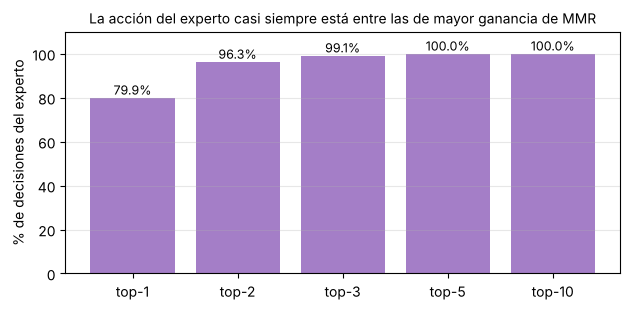

In [7]:
# ¿En qué posición del ranking de MMR (ganancia marginal) está la acción del experto?
N_, W_, T_ = D_val["P"].shape
g = (D_val["V"][:, None, None, :] * D_val["Q"][:, :, None, :] * D_val["P"][:, None, :, :])   # (N, pasos, W, T)
g = g.masked_fill(~D_val["FREE"].unsqueeze(-1), -1).reshape(N_, W_, W_ * T_)
g_exp = g.gather(2, D_val["Y"].unsqueeze(-1))
rank = (g > g_exp).sum(-1) + 1                                    # 1 = el par del experto es el de mayor ganancia
cobertura = {k: (rank <= k).float().mean().item() for k in (1, 2, 3, 5, 10)}
gap_mmr_val = gap([cost_of(i, mmr(i)) for i in val_insts], val_expert)
gap_rand_val = gap(agent_costs(make_random_eval(0), val_insts), val_expert)
print("Cobertura de la acción del experto en el top-k de MMR (3 000 decisiones de validación):")
for k, c in cobertura.items():
    print(f"  top-{k:<2}: {100 * c:5.1f} %")
print(f"\nGap en 100 instancias de validación: MMR {gap_mmr_val.mean():.2f} ± {gap_mmr_val.std():.2f} % | "
      f"aleatorio {gap_rand_val.mean():.1f} ± {gap_rand_val.std():.1f} %")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ks = list(cobertura)
ax.bar([f"top-{k}" for k in ks], [100 * cobertura[k] for k in ks], color="tab:purple", alpha=0.85)
for x, k in enumerate(ks):
    ax.text(x, 100 * cobertura[k] + 1.5, f"{100 * cobertura[k]:.1f}%", ha="center", fontsize=9)
ax.set_ylim(0, 110); ax.set_ylabel("% de decisiones del experto")
ax.set_title("La acción del experto casi siempre está entre las de mayor ganancia de MMR", fontsize=10)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); guardar(fig, "mmr_cobertura"); plt.show()
CRITERIO_MMR = {"cobertura": cobertura, "gap_mmr_val": float(gap_mmr_val.mean()),
                "gap_rand_val": float(gap_rand_val.mean())}

### 5.3 Variante B — decoder con atención eficiente (ISAB)

En la base, los pares solo se comparan en el softmax final: un par no "sabe" si existe otra arma libre que aproveche mejor su objetivo (lo que en el módulo 2 aportaban `arrepentimiento` y la self-attention entre filas). La variante B **re-contextualiza el estado en cada paso**: los pares factibles $Z_{ij}(t) = \mathrm{ReLU}(W_A h^w_i + W_B h_j(t) + W_E \tilde p_{ij})$ interactúan mediante un bloque **ISAB** (Induced Set Attention Block, Lee et al., 2019) con $m = 16$ puntos inductores aprendibles:

$$I' = \mathrm{LN}\big(I + \mathrm{MHA}(I, Z, Z)\big),\; I' \leftarrow \mathrm{LN}(I' + \mathrm{FF}(I')) \qquad Z' = \mathrm{LN}\big(Z + \mathrm{MHA}(Z, I', I')\big),\; Z' \leftarrow \mathrm{LN}(Z' + \mathrm{FF}(Z'))$$

El **contexto** pasa a ser el resumen de los puntos inductores, $c = W_c[\,\overline{I'} ; \text{progreso}\,]$ (reemplaza promedios + glimpse), y el puntero usa los pares contextualizados: $u_{ij} = C\tanh\big((W_r c)^\top W_k Z'_{ij}/\sqrt d\big)$.

**¿Por qué ISAB y no self-attention completa, LUNA o atención dispersa?** Una self-attention completa entre los $n = W\cdot T$ pares costaría $O(n^2 d)$ **en cada paso** (lo mismo que hacía, de hecho, el módulo 2), así que no cumple la exigencia de un decoder lineal. ISAB la reemplaza por dos atenciones cruzadas de costo $O(n\,m\,d)$. Lo elegimos frente a LUNA porque el estado del WTAP es un **conjunto** sin orden que cambia en cada paso (desaparecen los pares del arma recién asignada): no hay una secuencia ni una memoria que deba persistir entre capas, que es lo que aporta el depósito $P$ de LUNA, mientras que ISAB es justamente el bloque del *Set Transformer* para conjuntos y crea un resumen nuevo en cada capa. La atención dispersa necesitaría un criterio para decidir qué pares conectar, que es el papel del sesgo de la variante A; así cada variante aísla un efecto.

In [8]:
# chequeos de los modelos SIN entrenar
torch.manual_seed(0)
xb = {k: v[:16] for k, v in D_train.items()}
for name, variant in MODELOS.items():
    m = WTAPModel(variant).eval()
    with torch.no_grad():
        logits = m(xb["P"], xb["V"], xb["FREE"], xb["Q"])                                  # (16, W, W·T)
    probs = torch.softmax(logits, -1)
    valid = xb["FREE"].unsqueeze(-1).expand(-1, -1, -1, N_TARGETS).reshape(16, N_WEAPONS, -1)
    assert torch.allclose(probs.sum(-1), torch.ones(16, N_WEAPONS), atol=1e-5)
    assert probs[~valid].max() < 1e-12                                                    # pares inválidos con prob. 0
    ce = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), xb["Y"].reshape(-1)).item()
    ref = torch.log(valid.sum(-1).float()).mean().item()
    acc = (logits.argmax(-1) == xb["Y"]).float().mean().item()
    print(f"{name:<14} salida {tuple(logits.shape)} | CE inicial {ce:.3f} (uniforme: {ref:.3f}) | acc inicial {acc:.3f}")

# el mismo modelo acepta cualquier tamaño, y el encoder no depende del estado
inst20 = WTAP_Instance.random(20, 15, rng=np.random.RandomState(5))
P20 = torch.tensor(inst20.probs, dtype=torch.float32)[None]
V20 = torch.tensor(inst20.values, dtype=torch.float32)[None]
m = WTAPModel("B").eval()
with torch.no_grad():
    enc = m.encode(P20, V20)                                          # 1 sola vez
    free = torch.ones(1, 3, 20, dtype=torch.bool); free[0, 1, :5] = False; free[0, 2, :12] = False
    q = torch.rand(1, 3, 15)
    out = m.decode(enc, free, q)                                      # 3 estados distintos con el mismo encoder
print(f"\nInstancia 20×15: encoder 1 vez -> Hw {tuple(enc['Hw'].shape)}, Ht {tuple(enc['Ht'].shape)}; "
      f"decoder en 3 estados -> {tuple(out.shape)}; pares válidos por estado: {(out > -1e8).sum(-1).tolist()[0]}")

Base           salida (16, 10, 80) | CE inicial 3.590 (uniforme: 3.590) | acc inicial 0.031
A · sesgo MMR  salida (16, 10, 80) | CE inicial 2.817 (uniforme: 3.590) | acc inicial 0.819
B · ISAB       salida (16, 10, 80) | CE inicial 3.590 (uniforme: 3.590) | acc inicial 0.031

Instancia 20×15: encoder 1 vez -> Hw (1, 20, 64), Ht (1, 15, 64); decoder en 3 estados -> (1, 3, 300); pares válidos por estado: [300, 225, 120]


## 6. Punto 2 — Complejidad temporal del encoder y del decoder

Sea $n = W\cdot T$ (tamaño de la matriz $p$ = número de acciones), $d$ la dimensión, $L$ las capas y $m$ los puntos inductores.

| Modelo | Encoder (1 vez por instancia) | Cómputo por paso del decoder | Por instancia (W pasos) |
|---|---|---|---|
| Módulo 2 | — (todo se recalcula en cada paso) | `state2vec` $O(W^2T)$ + self-attention $O(L\,n^2 d)$ | $O(W\,n^2 d)$ |
| **Base** | $O(L\,(n\,d + (W+T)\,d^2))$ | $O(n\,d + (W+T)\,d^2)$ → **lineal** | $O(W\,n\,d)$ |
| **A · sesgo MMR** | igual a la base $+\,O(L\,n)$ | base $+\,O(n)$ (ganancias) → **lineal** | $O(W\,n\,d)$ |
| **B · ISAB** | igual a la base | $O(n\,m\,d + n\,d^2)$ → **lineal** | $O(W\,n\,m\,d)$ |
| B con self-attention completa | igual a la base | $O(n^2 d)$ → cuadrático | $O(W\,n^2 d)$ |

El encoder de los nuevos modelos es incluso **lineal** en $n$ (la atención es bipartita: cada arma mira $T$ objetivos y cada objetivo $W$ armas), aunque la tarea permitiría uno cuadrático. El decoder es lineal en $n$, que es el mínimo posible porque debe entregar un logit por acción. La única pieza cuadrática que aparecería en el decoder es la interacción entre pares de la variante B, y por eso la implementamos con ISAB.

**Medición.** Como en el material del curso, fijamos PyTorch a **1 hilo** para que el tiempo refleje la complejidad algorítmica. Con pesos aleatorios (el tiempo no depende del entrenamiento) medimos la mediana de varias repeticiones del **encoder** y de **un paso del decoder** en tamaños de 5×4 a 300×200 ($n$ = 20 a 60 000). Para el módulo 2 medimos un paso completo (`state2vec` + red), y como ablación medimos la variante B con **self-attention completa** entre pares en lugar de ISAB; ambos diseños cuadráticos se miden hasta 70×50 ($n$ = 3 500). Las pendientes se ajustan en escala log-log con los 4 tamaños más grandes de cada curva: 1 = lineal, 2 = cuadrático.

In [9]:
def median_time(fn, reps=5):
    fn()                                                   # calentamiento
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)


def time_new(model, inst, reps=5):
    W, T = inst.probs.shape
    P = torch.tensor(inst.probs, dtype=torch.float32)[None]
    V = torch.tensor(inst.values, dtype=torch.float32)[None]
    free, q = torch.ones(1, 1, W, dtype=torch.bool), torch.ones(1, 1, T)
    with torch.no_grad():
        t_enc = median_time(lambda: model.encode(P, V), reps)
        enc = model.encode(P, V)
        t_dec = median_time(lambda: model.decode(enc, free, q), reps)
    return t_enc, t_dec


def time_mod2(model, inst, reps=3):
    st = WTAP_State(inst)
    with torch.no_grad():
        t_feat = median_time(lambda: state2vec(st), reps)
        x = torch.tensor(state2vec(st))
        t_net = median_time(lambda: model(x), reps)
    return t_feat, t_net


SIZES_TIME = [(5, 4), (10, 8), (15, 10), (20, 15), (30, 20), (40, 30), (50, 40), (70, 50), (100, 80),
              (150, 120), (200, 160), (300, 200)]
N_MAX_QUAD = 3500                       # los diseños cuadráticos se miden hasta n = 3 500 (70×50)
if RAPIDO:
    SIZES_TIME = SIZES_TIME[:8]
SHORT = {"Base": "Base", "A · sesgo MMR": "A", "B · ISAB": "B", "B con atención completa": "B-completa"}
torch.set_num_threads(1)
torch.manual_seed(0)
timing_models = {name: WTAPModel(v).eval() for name, v in MODELOS.items()}
timing_models["B con atención completa"] = WTAPModel("B", full_attention=True).eval()
mod2 = WTAP_Attention().eval()
TIMES = {name: {"n": [], "W": [], "enc": [], "dec": []} for name in timing_models}
TIMES["Módulo 2"] = {"n": [], "W": [], "feat": [], "net": [], "dec": []}
t_start = time.time()
for (W, T) in SIZES_TIME:
    inst = WTAP_Instance.random(W, T, rng=np.random.RandomState(W * 1000 + T))
    n = W * T
    line = f"{W:>3}×{T:<3} n={n:6d} |"
    for name, model in timing_models.items():
        if name == "B con atención completa" and n > N_MAX_QUAD:
            continue
        te, td = time_new(model, inst, reps=5 if n <= 8000 else 3)
        for key, val in zip(("n", "W", "enc", "dec"), (n, W, te, td)):
            TIMES[name][key].append(val)
        line += f" {SHORT[name]} {1e3 * td:7.2f} |"
    if n <= N_MAX_QUAD:
        tf, tn = time_mod2(mod2, inst)
        for key, val in zip(("n", "W", "feat", "net", "dec"), (n, W, tf, tn, tf + tn)):
            TIMES["Módulo 2"][key].append(val)
        line += f" Módulo 2 {1e3 * (tf + tn):8.2f} (features {1e3 * tf:.2f})"
    print(line + "   [ms por decisión]", flush=True)
torch.set_num_threads(N_THREADS)
print(f"Mediciones en {time.time() - t_start:.0f} s (1 hilo)")

  5×4   n=    20 | Base    0.30 | A    0.37 | B    0.49 | B-completa    0.27 | Módulo 2     0.36 (features 0.10)   [ms por decisión]


 10×8   n=    80 | Base    0.31 | A    0.31 | B    0.56 | B-completa    0.53 | Módulo 2     0.56 (features 0.14)   [ms por decisión]


 15×10  n=   150 | Base    0.35 | A    0.31 | B    0.65 | B-completa    1.01 | Módulo 2     0.79 (features 0.17)   [ms por decisión]


 20×15  n=   300 | Base    0.34 | A    0.37 | B    0.91 | B-completa    2.73 | Módulo 2     1.46 (features 0.22)   [ms por decisión]


 30×20  n=   600 | Base    0.48 | A    0.40 | B    1.24 | B-completa    8.97 | Módulo 2     3.58 (features 0.28)   [ms por decisión]


 40×30  n=  1200 | Base    0.47 | A    0.47 | B    2.20 | B-completa   42.36 | Módulo 2    10.15 (features 0.42)   [ms por decisión]


... (3 outputs left out)

150×120 n= 18000 | Base    2.38 | A    2.45 | B   22.73 |   [ms por decisión]


200×160 n= 32000 | Base    3.68 | A    3.79 | B   54.11 |   [ms por decisión]


300×200 n= 60000 | Base   14.40 | A   14.16 | B  121.25 |   [ms por decisión]


Mediciones en 6 s (1 hilo)


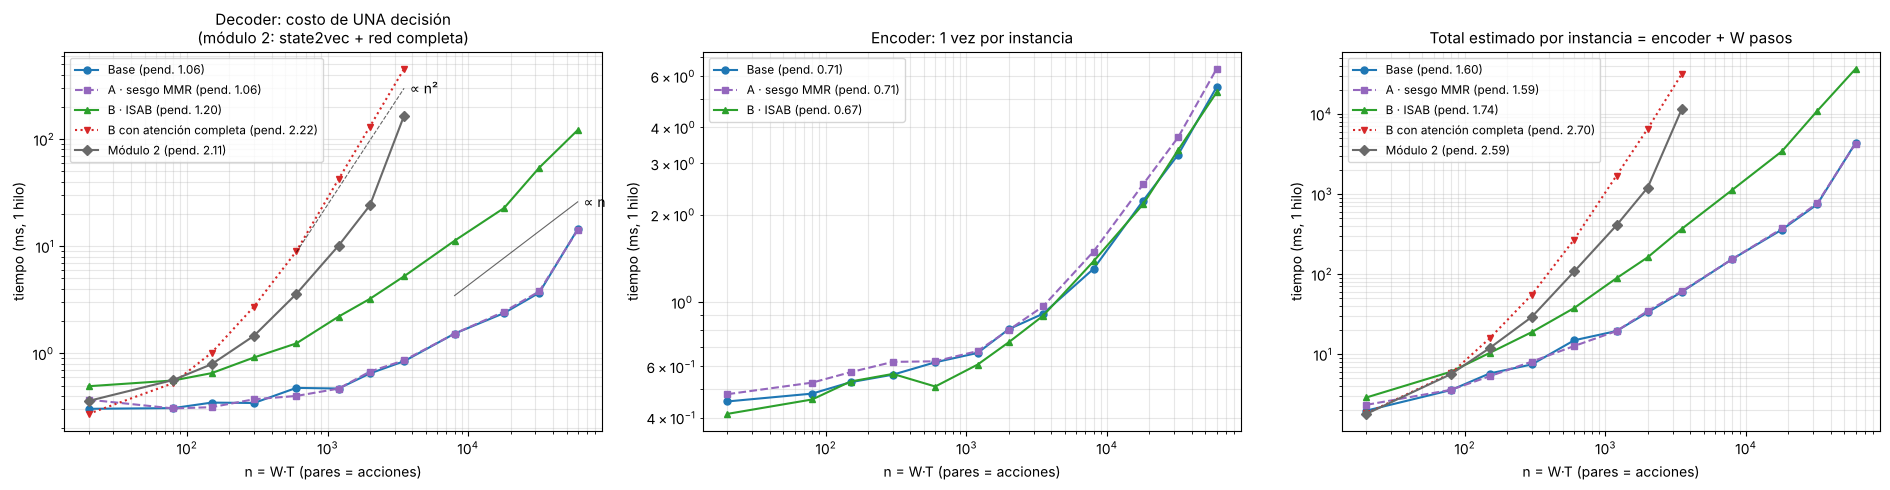

Modelo                   pend. paso pend. encoder pend. total   (4 tamaños más grandes)
Base                           1.06          0.71        1.60
A · sesgo MMR                  1.06          0.71        1.59
B · ISAB                       1.20          0.67        1.74
B con atención completa        2.22          0.20        2.70
Módulo 2                       2.11           nan        2.59

10×8: una decisión cuesta 0.56 ms en el módulo 2 y 0.31 ms en la base (+ encoder 0.48 ms, una vez). Por instancia: 5.6 ms vs 3.6 ms -> la base es 1.6× más rápida

50×40: una decisión cuesta 24.04 ms en el módulo 2 y 0.65 ms en la base (+ encoder 0.81 ms, una vez). Por instancia: 1202.0 ms vs 33.2 ms -> la base es 36.2× más rápida


In [10]:
def slope(ns, ts, k=4):
    # pendiente log-log en los k tamaños más grandes medidos (régimen asintótico)
    ns, ts = np.asarray(ns, float)[-k:], np.asarray(ts, float)[-k:]
    return float(np.polyfit(np.log(ns), np.log(ts), 1)[0])

ESTILO_T = {"Base": ("tab:blue", "o-"), "A · sesgo MMR": ("tab:purple", "s--"), "B · ISAB": ("tab:green", "^-"),
            "B con atención completa": ("tab:red", "v:"), "Módulo 2": ("dimgray", "D-")}
for name, t in TIMES.items():           # total estimado por instancia: encoder (1 vez) + W pasos del decoder
    enc = t["enc"] if name != "Módulo 2" else [0.0] * len(t["n"])
    t["total"] = [e + W_ * d_ for e, W_, d_ in zip(enc, t["W"], t["dec"])]
SLOPES = {name: slope(TIMES[name]["n"], TIMES[name]["dec"]) for name in TIMES}
SLOPES_ENC = {name: slope(TIMES[name]["n"], TIMES[name]["enc"]) for name in timing_models}
SLOPES_TOTAL = {name: slope(TIMES[name]["n"], TIMES[name]["total"]) for name in TIMES}

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for name, (col, sty) in ESTILO_T.items():
    t = TIMES[name]
    axes[0].plot(t["n"], 1e3 * np.array(t["dec"]), sty, color=col, ms=5, label=f"{name} (pend. {SLOPES[name]:.2f})")
    axes[2].plot(t["n"], 1e3 * np.array(t["total"]), sty, color=col, ms=5, label=f"{name} (pend. {SLOPES_TOTAL[name]:.2f})")
    if name in ("Base", "A · sesgo MMR", "B · ISAB"):
        axes[1].plot(t["n"], 1e3 * np.array(t["enc"]), sty, color=col, ms=5, label=f"{name} (pend. {SLOPES_ENC[name]:.2f})")
nb_, tb_ = TIMES["Base"]["n"], TIMES["Base"]["dec"]                  # rectas de referencia ancladas a las mediciones
x1 = np.array([nb_[-4], nb_[-1]], float)
axes[0].plot(x1, 1e3 * tb_[-1] * 1.8 * x1 / x1[-1], "k-", lw=0.8, alpha=0.6)
axes[0].text(x1[-1] * 1.1, 1e3 * tb_[-1] * 1.8, "∝ n", fontsize=10, va="center")
nm_, tm_ = TIMES["Módulo 2"]["n"], TIMES["Módulo 2"]["dec"]
x2 = np.array([nm_[-4], nm_[-1]], float)
axes[0].plot(x2, 1e3 * tm_[-1] * 1.8 * (x2 / x2[-1]) ** 2, "k--", lw=0.8, alpha=0.6)
axes[0].text(x2[-1] * 1.1, 1e3 * tm_[-1] * 1.8, "∝ n²", fontsize=10, va="center")
titles = ["Decoder: costo de UNA decisión\n(módulo 2: state2vec + red completa)", "Encoder: 1 vez por instancia",
          "Total estimado por instancia = encoder + W pasos"]
for ax, ttl in zip(axes, titles):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(alpha=0.3, which="both")
    ax.set_xlabel("n = W·T (pares = acciones)"); ax.set_ylabel("tiempo (ms, 1 hilo)")
    ax.set_title(ttl, fontsize=11); ax.legend(fontsize=8.5)
plt.tight_layout(); guardar(fig, "complejidad"); plt.show()

print(f"{'Modelo':<24} {'pend. paso':>10} {'pend. encoder':>13} {'pend. total':>11}   (4 tamaños más grandes)")
for name in TIMES:
    print(f"{name:<24} {SLOPES[name]:>10.2f} {SLOPES_ENC.get(name, float('nan')):>13.2f} {SLOPES_TOTAL[name]:>11.2f}")
SPEEDUP = {}
for (W, T) in [(10, 8), (50, 40)]:
    n = W * T
    kb, km = TIMES["Base"]["n"].index(n), TIMES["Módulo 2"]["n"].index(n)
    SPEEDUP[f"{W}×{T}"] = TIMES["Módulo 2"]["total"][km] / TIMES["Base"]["total"][kb]
    print(f"\n{W}×{T}: una decisión cuesta {1e3 * TIMES['Módulo 2']['dec'][km]:.2f} ms en el módulo 2 y "
          f"{1e3 * TIMES['Base']['dec'][kb]:.2f} ms en la base (+ encoder {1e3 * TIMES['Base']['enc'][kb]:.2f} ms, una vez). "
          f"Por instancia: {1e3 * TIMES['Módulo 2']['total'][km]:.1f} ms vs {1e3 * TIMES['Base']['total'][kb]:.1f} ms "
          f"-> la base es {SPEEDUP[f'{W}×{T}']:.1f}× más rápida")

## 7. Punto 4 — Entrenamiento con la misma configuración

Los tres modelos se entrenan con **exactamente la misma configuración**; solo cambia la arquitectura. Cada época recorre las 6 000 instancias (60 000 decisiones) con *teacher forcing*. Además de la pérdida y el accuracy, medimos en cada época el **gap del rollout greedy** en 100 instancias de validación, que es la métrica que de verdad interesa. Repetimos con 3 semillas de inicialización para medir la estabilidad.

| Hiperparámetro | Valor (igual para los 3 modelos) |
|---|---|
| $d$ / cabezas / capas de encoder / FF | 64 / 4 / 2 / 64→128→64 |
| Normalización · recorte de logits | LayerNorm post-residual · $C = 10$ |
| Datos | 6 000 instancias 10×8 de entrenamiento (60 000 decisiones), 300 de validación (3 000) |
| Optimizador · tasa de aprendizaje | Adam · $10^{-3}$, `ReduceLROnPlateau` sobre la pérdida de validación (factor 0,5, paciencia 3, mínimo $10^{-5}$), como `sl_train` del material |
| Inicialización del puntero | $W_r = 0$: los logits parten en 0, la política inicial es uniforme sobre las acciones válidas |
| Batch | 32 instancias (320 decisiones) |
| Recorte de gradiente | norma 1,0 |
| Épocas · early stopping | máx. 60 · paciencia 8 sobre la pérdida de validación (min_delta $10^{-3}$), restaura la mejor época |
| Pérdida | entropía cruzada sobre los $W\cdot T$ logits enmascarados |
| Semillas | 0, 1, 2 (inicialización y orden de los batches); los datos son los mismos |
| Específicos de cada variante | A: $\alpha$ inicia en 1 y $\alpha^{(l,\text{dir},h)}$ en 0 · B: $m = 16$ puntos inductores |

In [11]:
TRAIN_CFG = dict(lr=1e-3, batch_size=32, max_epochs=15 if RAPIDO else 60, patience=8, min_delta=1e-3, grad_clip=1.0,
                 lr_factor=0.5, lr_patience=3, lr_min=1e-5)


def to_dev(D, idx):
    return [D[k][idx].to(device) for k in ("P", "V", "FREE", "Q", "Y")]


def eval_loss_acc(model, D, bs=256):
    model.eval()
    loss, hits, n = 0.0, 0, 0
    with torch.no_grad():
        for s in range(0, len(D["Y"]), bs):
            P, V, FR, Q, Y = to_dev(D, slice(s, s + bs))
            logits = model(P, V, FR, Q)
            loss += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), Y.reshape(-1), reduction="sum").item()
            hits += (logits.argmax(-1) == Y).sum().item(); n += Y.numel()
    return loss / n, hits / n


@torch.no_grad()
def rollout(model, insts, bs=128):
    # greedy batcheado: encoder 1 vez por instancia y luego W pasos del decoder (instancias del mismo tamaño)
    model.eval()
    out = []
    for s in range(0, len(insts), bs):
        chunk = insts[s:s + bs]
        P = torch.tensor(np.stack([i.probs for i in chunk]), dtype=torch.float32, device=device)
        V = torch.tensor(np.stack([i.values for i in chunk]), dtype=torch.float32, device=device)
        B, W, T = P.shape
        enc = model.encode(P, V)
        free = torch.ones(B, W, dtype=torch.bool, device=device)
        q = torch.ones(B, T, device=device)
        assign = torch.full((B, W), -1, dtype=torch.long, device=device)
        ar = torch.arange(B, device=device)
        for _ in range(W):
            a = model.decode(enc, free[:, None], q[:, None])[:, 0].argmax(-1)
            i, j = a // T, a % T
            assign[ar, i] = j; free[ar, i] = False
            q[ar, j] = q[ar, j] * (1 - P[ar, i, j])
        out += assign.cpu().tolist()
    return out


def rollout_costs(model, insts):
    return np.array([cost_of(inst, a) for inst, a in zip(insts, rollout(model, insts))])


def train_model(variant, seed, D_train=D_train, D_val=D_val, cfg=TRAIN_CFG, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = WTAPModel(variant).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=cfg["lr_factor"],
                                                       patience=cfg["lr_patience"], min_lr=cfg["lr_min"])
    gen = torch.Generator().manual_seed(seed)
    H = {k: [] for k in ("train_loss", "val_loss", "train_acc", "val_acc", "val_gap", "alpha", "lr", "time")}
    vl, va = eval_loss_acc(model, D_val)                                    # época 0 = sin entrenar
    H["init"] = {"val_loss": vl, "val_acc": va, "val_gap": float(gap(rollout_costs(model, val_insts), val_expert).mean())}
    best, best_state, best_ep, bad, t0 = float("inf"), None, 0, 0, time.time()
    for ep in range(1, cfg["max_epochs"] + 1):
        model.train()
        tl, th, tn = 0.0, 0, 0
        for idx in torch.randperm(len(D_train["Y"]), generator=gen).split(cfg["batch_size"]):
            P, V, FR, Q, Y = to_dev(D_train, idx)
            logits = model(P, V, FR, Q)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), Y.reshape(-1))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            tl += loss.item() * Y.numel(); th += (logits.argmax(-1) == Y).sum().item(); tn += Y.numel()
        vl, va = eval_loss_acc(model, D_val)
        vg = float(gap(rollout_costs(model, val_insts), val_expert).mean())
        for k, v in zip(("train_loss", "val_loss", "train_acc", "val_acc", "val_gap", "lr", "time"),
                        (tl / tn, vl, th / tn, va, vg, opt.param_groups[0]["lr"], time.time() - t0)):
            H[k].append(v)
        sched.step(vl)
        if variant == "A":
            H["alpha"].append(float(model.alpha_out.detach()))
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"  [{variant} · semilla {seed}] época {ep:2d} | loss {tl / tn:.3f} / {vl:.3f} | acc {th / tn:.3f} / {va:.3f} "
                  f"| gap val {vg:5.2f} %" + (f" | α = {H['alpha'][-1]:.2f}" if variant == "A" else "")
                  + f" | {time.time() - t0:.0f} s", flush=True)
        if vl < best - cfg["min_delta"]:
            best, best_ep, bad, best_state = vl, ep, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    H["best_epoch"], H["epochs"] = best_ep, len(H["val_loss"])
    if variant == "A":
        H["alpha_enc"] = model.alpha_enc.detach().cpu().numpy().tolist()
    return model.cpu().eval(), H


RUNS = {name: [] for name in MODELOS}                  # RUNS[nombre] = [(modelo, historial) por semilla]
t_all = time.time()
for name, variant in MODELOS.items():
    for seed in range(N_SEEDS):
        print(f"\n=== {name} · semilla {seed} ===")
        model, H = train_model(variant, seed)
        RUNS[name].append((model, H))
        print(f"  -> mejor época {H['best_epoch']} de {H['epochs']} | loss val {H['val_loss'][H['best_epoch'] - 1]:.3f} "
              f"| acc val {H['val_acc'][H['best_epoch'] - 1]:.3f} | {H['time'][-1] / 60:.1f} min")
print(f"\nEntrenamiento total: {(time.time() - t_all) / 60:.1f} min en {device}")
MODEL = {name: RUNS[name][0][0] for name in MODELOS}    # semilla 0: se usa para verificar el GreedyAgent (sección 9)


=== Base · semilla 0 ===


  [base · semilla 0] época  1 | loss 0.718 / 0.507 | acc 0.761 / 0.807 | gap val  4.89 % | 3 s


  [base · semilla 0] época  5 | loss 0.454 / 0.458 | acc 0.830 / 0.819 | gap val  3.98 % | 20 s


  [base · semilla 0] época 10 | loss 0.427 / 0.424 | acc 0.837 / 0.836 | gap val  2.86 % | 36 s


  [base · semilla 0] época 15 | loss 0.407 / 0.419 | acc 0.845 / 0.838 | gap val  3.26 % | 58 s


  [base · semilla 0] época 20 | loss 0.382 / 0.373 | acc 0.854 / 0.857 | gap val  2.87 % | 79 s


... (109 outputs left out)

  [B · semilla 2] época 50 | loss 0.274 / 0.304 | acc 0.892 / 0.881 | gap val  2.61 % | 787 s


  [B · semilla 2] época 55 | loss 0.263 / 0.294 | acc 0.896 / 0.886 | gap val  2.36 % | 868 s


  [B · semilla 2] época 60 | loss 0.256 / 0.290 | acc 0.900 / 0.882 | gap val  2.40 % | 947 s


  -> mejor época 58 de 60 | loss val 0.287 | acc val 0.885 | 15.8 min

Entrenamiento total: 62.7 min en cpu


In [12]:
print(f"{'Modelo':<14} {'semilla':>7} {'épocas':>7} {'mejor':>6} {'loss val':>9} {'acc val':>8} {'gap val %':>10} {'min':>6}")
for name in MODELOS:
    for seed, (m, H) in enumerate(RUNS[name]):
        b = H["best_epoch"] - 1
        print(f"{name:<14} {seed:>7} {H['epochs']:>7} {H['best_epoch']:>6} {H['val_loss'][b]:>9.3f} {H['val_acc'][b]:>8.3f} "
              f"{H['val_gap'][b]:>10.2f} {H['time'][-1] / 60:>6.1f}")

Modelo         semilla  épocas  mejor  loss val  acc val  gap val %    min
Base                 0      59     51     0.324    0.874       2.16    3.6
Base                 1      60     53     0.310    0.873       2.27    3.5
Base                 2      54     46     0.315    0.875       2.30    3.2
A · sesgo MMR        0      60     58     0.301    0.879       2.38    3.8
A · sesgo MMR        1      60     53     0.317    0.873       1.85    3.6
A · sesgo MMR        2      52     44     0.315    0.876       2.24    3.2
B · ISAB             0      60     56     0.298    0.880       2.16   14.7
B · ISAB             1      46     38     0.296    0.880       2.05   11.3
B · ISAB             2      60     58     0.287    0.885       2.33   15.8


## 8. Punto 5 — Convergencia

Curvas por época de los tres modelos (línea = media de las semillas, banda = mínimo–máximo). La época 0 es el modelo sin entrenar.

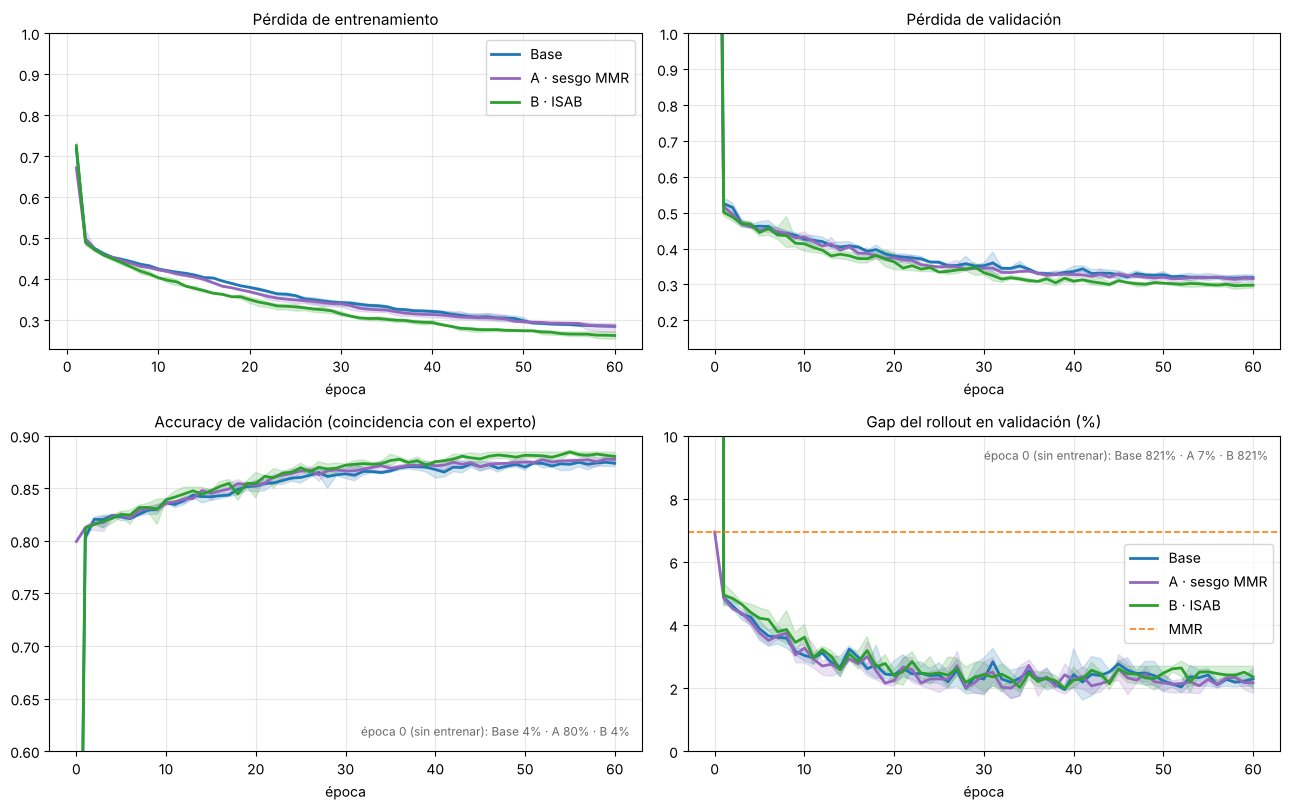

In [13]:
def curve(name, key):
    # matriz (semillas, épocas) rellenando con el último valor si alguna semilla se detuvo antes;
    # las métricas de validación incluyen la época 0 (modelo sin entrenar)
    hs = [H for _, H in RUNS[name]]
    L = max(len(H[key]) for H in hs)
    M = np.array([H[key] + [H[key][-1]] * (L - len(H[key])) for H in hs])
    if key in ("val_loss", "val_acc", "val_gap"):
        M = np.concatenate([np.array([[H["init"][key]] for H in hs]), M], axis=1)
        return np.arange(L + 1), M
    return np.arange(1, L + 1), M

fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
panels = [("train_loss", "Pérdida de entrenamiento"), ("val_loss", "Pérdida de validación"),
          ("val_acc", "Accuracy de validación (coincidencia con el experto)"), ("val_gap", "Gap del rollout en validación (%)")]
for ax, (key, title) in zip(axes.flat, panels):
    for name in MODELOS:
        ep, M = curve(name, key)
        mean = np.nanmean(M, 0)
        ax.plot(ep, mean, color=COLORES[name], label=name, lw=2)
        if M.shape[0] > 1:
            ax.fill_between(ep, np.nanmin(M, 0), np.nanmax(M, 0), color=COLORES[name], alpha=0.18)
    ax.set_title(title, fontsize=11); ax.set_xlabel("época"); ax.grid(alpha=0.3)
axes[0, 0].set_ylim(top=1.0); axes[0, 1].set_ylim(top=1.0)
axes[1, 1].axhline(CRITERIO_MMR["gap_mmr_val"], color=COLORES["MMR"], ls="--", lw=1.2, label="MMR")
init_txt = {key: " · ".join(f"{n.split(' ')[0]} {np.mean([H['init'][key] for _, H in RUNS[n]]) * (100 if key == 'val_acc' else 1):.0f}"
                            + ("%" if key in ("val_acc", "val_gap") else "") for n in MODELOS)
            for key in ("val_acc", "val_gap", "val_loss")}
for ax, key in [(axes[1, 0], "val_acc"), (axes[1, 1], "val_gap")]:
    ax.text(0.98, 0.04 if key == "val_acc" else 0.96, "época 0 (sin entrenar): " + init_txt[key], transform=ax.transAxes,
            ha="right", va="bottom" if key == "val_acc" else "top", fontsize=8.5, color="dimgray")
axes[1, 1].set_ylim(0, max(10, CRITERIO_MMR["gap_mmr_val"] * 1.4))
axes[1, 0].set_ylim(0.6, 0.9)
axes[0, 0].legend(); axes[1, 1].legend()
plt.tight_layout(); guardar(fig, "convergencia"); plt.show()

Épocas (una por semilla) hasta cada umbral; 'min' = minutos de reloj hasta gap val < 3 % (media de las semillas)
Modelo         gap ép. 0   gap<MMR      gap<3 %    loss<0,35  mejor época  mejor loss val oscil. gap  s/época   min
Base              821.0% [1, 1, 1] [10, 11, 13] [26, 28, 32] [51, 53, 46]   0.317 ± 0.006       0.22      3.6   0.7
A · sesgo MMR       6.9% [1, 1, 1]  [12, 11, 9] [28, 25, 25] [58, 53, 44]   0.311 ± 0.007       0.29      3.7   0.7
B · ISAB          821.0% [1, 1, 1] [11, 13, 14] [20, 24, 21] [56, 38, 58]   0.293 ± 0.005       0.29     15.1   3.2


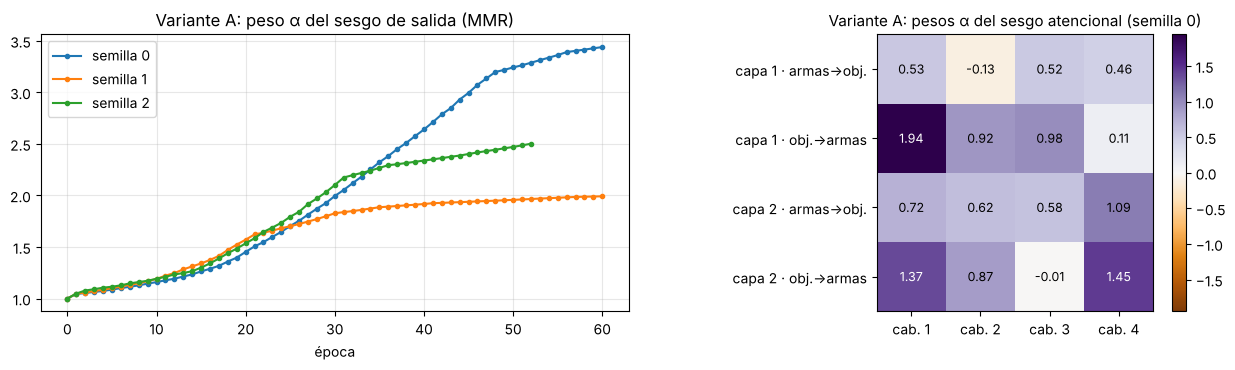

α del sesgo de salida al final del entrenamiento: semilla 0: 3.41 | semilla 1: 1.97 | semilla 2: 2.39 (mejor época; parte en 1)


In [14]:
def first_epoch(values, cond):
    for k, v in enumerate(values, start=1):
        if cond(v):
            return k
    return None

CONV = {}
print("Épocas (una por semilla) hasta cada umbral; 'min' = minutos de reloj hasta gap val < 3 % (media de las semillas)")
print(f"{'Modelo':<14} {'gap ép. 0':>9} {'gap<MMR':>9} {'gap<3 %':>12} {'loss<0,35':>12} {'mejor época':>12} "
      f"{'mejor loss val':>15} {'oscil. gap':>10} {'s/época':>8} {'min':>5}")
for name in MODELOS:
    hs = [H for _, H in RUNS[name]]
    g0 = np.mean([H["init"]["val_gap"] for H in hs])
    e_gap = [first_epoch(H["val_gap"], lambda v: v < CRITERIO_MMR["gap_mmr_val"]) for H in hs]
    e_gap3 = [first_epoch(H["val_gap"], lambda v: v < 3.0) for H in hs]
    e_l35 = [first_epoch(H["val_loss"], lambda v: v < 0.35) for H in hs]
    e_acc = [first_epoch(H["val_acc"], lambda v: v >= 0.85) for H in hs]
    best_l = [H["val_loss"][H["best_epoch"] - 1] for H in hs]
    osc = [np.mean(np.abs(np.diff(H["val_loss"][-10:]))) for H in hs]          # |Δ loss val| medio, últimas 10 épocas
    osc_g = [np.mean(np.abs(np.diff(H["val_gap"][-10:]))) for H in hs]        # |Δ gap val| medio, últimas 10 épocas
    sec = [H["time"][-1] / H["epochs"] for H in hs]
    min_gap3 = [e * s / 60 for e, s in zip(e_gap3, sec) if e is not None]
    CONV[name] = {"gap_init": float(g0), "epoch_gap_below_mmr": e_gap, "epoch_gap_below_3": e_gap3,
                  "epoch_loss_below_035": e_l35, "epoch_acc_085": e_acc,
                  "best_epoch": [H["best_epoch"] for H in hs], "epochs": [H["epochs"] for H in hs],
                  "best_val_loss_mean": float(np.mean(best_l)), "best_val_loss_std": float(np.std(best_l)),
                  "best_val_acc": [H["val_acc"][H["best_epoch"] - 1] for H in hs],
                  "best_val_gap": [H["val_gap"][H["best_epoch"] - 1] for H in hs],
                  "oscillation": float(np.mean(osc)), "oscillation_gap": float(np.mean(osc_g)),
                  "sec_per_epoch": float(np.mean(sec)), "minutes_to_gap3": float(np.mean(min_gap3)) if min_gap3 else None,
                  "train_minutes": [H["time"][-1] / 60 for H in hs]}
    print(f"{name:<14} {g0:>8.1f}% {str(e_gap):>9} {str(e_gap3):>12} {str(e_l35):>12} {str(CONV[name]['best_epoch']):>12} "
          f"{np.mean(best_l):>7.3f} ± {np.std(best_l):.3f} {np.mean(osc_g):>10.2f} {np.mean(sec):>8.1f} "
          f"{np.mean(min_gap3) if min_gap3 else float('nan'):>5.1f}")

if "A · sesgo MMR" in RUNS:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
    for seed, (m, H) in enumerate(RUNS["A · sesgo MMR"]):
        axes[0].plot(range(0, len(H["alpha"]) + 1), [1.0] + H["alpha"], marker=".", label=f"semilla {seed}")
    axes[0].set_title("Variante A: peso α del sesgo de salida (MMR)"); axes[0].set_xlabel("época"); axes[0].grid(alpha=0.3)
    axes[0].legend()
    ae = np.array(RUNS["A · sesgo MMR"][0][1]["alpha_enc"])            # (capas, dirección, cabezas)
    M_ae, vmax = ae.reshape(-1, ae.shape[-1]), np.abs(ae).max()
    im = axes[1].imshow(M_ae, cmap="PuOr", vmin=-vmax, vmax=vmax)
    axes[1].set_yticks(range(ae.shape[0] * 2))
    axes[1].set_yticklabels([f"capa {l + 1} · {d}" for l in range(ae.shape[0]) for d in ("armas→obj.", "obj.→armas")])
    axes[1].set_xticks(range(ae.shape[-1])); axes[1].set_xticklabels([f"cab. {h + 1}" for h in range(ae.shape[-1])])
    for (r, c), v in np.ndenumerate(M_ae):
        axes[1].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if abs(v) > 0.6 * vmax else "black")
    axes[1].set_title("Variante A: pesos α del sesgo atencional (semilla 0)", fontsize=11)
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    plt.tight_layout(); guardar(fig, "alpha"); plt.show()
    print("α del sesgo de salida al final del entrenamiento:",
          " | ".join(f"semilla {s}: {H['alpha'][H['best_epoch'] - 1]:.2f}" for s, (_, H) in enumerate(RUNS["A · sesgo MMR"])),
          "(mejor época; parte en 1)")

**Análisis de la convergencia.** Los tres modelos se entrenaron con la misma configuración y 3 semillas cada uno.

- **Punto de partida.** Sin entrenar, la base y B tienen logits constantes (el puntero parte con $W_r = 0$), así que el rollout greedy manda todas las armas al primer objetivo: gap de 821 %. Gracias al sesgo de salida, la variante A parte exactamente desde la política de MMR (gap 6,9 %, accuracy 80 %).
- **Velocidad en épocas.** La ventaja inicial de A dura una época: después de la primera, los tres modelos ya superan a MMR (gap de validación 4,6–5,3 %) y las curvas de gap de la base y de A casi coinciden (media de las épocas 1–10: 3,90 % y 3,88 %; B 4,19 %). A llega a un gap < 3 % en 9–12 épocas, la base en 10–13 y B en 11–14. En la pérdida el orden cambia: B es la que baja más rápido (pérdida < 0,35 en 20–24 épocas, contra 25–28 de A y 26–32 de la base) y la que termina más abajo (0,293 ± 0,005 vs 0,311 ± 0,007 y 0,317 ± 0,006), con la mayor accuracy (88,0–88,5 % vs 87,3–87,9 %).
- **Velocidad en tiempo de reloj.** Una época de B cuesta 4,2 veces más (15,1 s vs 3,6–3,7 s): tarda 3,2 min en llegar a un gap < 3 %, contra 0,7 min de la base y de A, y sus 3 semillas tomaron 42 min, contra 10–11 min.
- **Estabilidad.** Las 9 corridas convergen sin divergencias: la mejor pérdida varía poco entre semillas (desviación 0,005–0,007) y, en el tramo final, la pérdida de validación oscila ≈ 0,005 entre épocas. El gap del rollout es más ruidoso (0,22–0,29 pp entre épocas; la base es la más estable) porque depende de pocas decisiones críticas por instancia. Por lo mismo, la menor pérdida de B no se traduce en un menor gap de validación: los tres terminan en niveles parecidos (media de las últimas 10 épocas: base 2,28 %, A 2,19 % y B 2,35 %).
- **Duración.** El early stopping se activó en 4 de las 9 corridas; las otras 5 llegaron al máximo de 60 épocas con la mejor época entre la 53 y la 58, es decir, todavía mejoraban levemente. El presupuesto es el mismo para los tres modelos, así que la comparación es justa.
- **α de la variante A.** El peso del sesgo de salida crece de 1 a 2,0–3,4 durante el entrenamiento y 14 de los 16 pesos del sesgo atencional (semilla 0) terminan positivos: el modelo usa el criterio de MMR en el encoder y en el decoder, y le da cada vez más peso.

## 9. Punto 6 — Evaluación con instancias de distintos tamaños

Los modelos se entrenaron **solo con 10×8**. Como ningún peso depende de W ni de T, los evaluamos sin cambios en 7 tamaños, de 5×4 a 100×80. Usamos **las mismas instancias del proyecto del módulo 2** (30 por tamaño con semilla 3000 + W, y las 50 de prueba en 10×8), así que la fila "Módulo 2" de las tablas es directamente comparable; 50×40 y 100×80 son nuevos. La referencia es el **experto ILS** (el algoritmo de las tareas anteriores; óptimo en todas las instancias verificadas de 5×4 y 10×8, y "mejor solución conocida" en las grandes): $\text{gap} = 100\,(\text{costo}/\text{costo ILS} - 1)$. Evaluamos con el rollout greedy **los 3 modelos entrenados de cada arquitectura** (semillas 0, 1 y 2) y comparamos con MMR y un constructivo aleatorio. Las tablas reportan la media y la desviación estándar sobre las 3 semillas × N instancias (90 ejecuciones por tamaño; 150 en 10×8), y aparte la variación del gap medio entre semillas.

Primero verificamos que el rollout batcheado coincide con el `GreedyAgent` de `eda` y que, en ese agente, **el encoder se ejecuta una sola vez por instancia** (caché por instancia).

In [15]:
class ModelEvalActions:
    # evaluador para el GreedyAgent de eda: encoder 1 vez por instancia (caché) y decoder en cada paso
    def __init__(self, model):
        self.model, self.cache, self.n_encoder_calls, self.n_decoder_calls = model, {}, 0, 0

    def __call__(self, states, env):
        single = not isinstance(states, list)
        if single:
            states = [states]
        evals = [[] for _ in states]
        groups = {}
        for k, s in enumerate(states):
            if not s.is_complete:
                groups.setdefault(s.inst_info.probs.shape, []).append(k)
        self.model.eval()
        with torch.no_grad():
            for (W, T), ks in groups.items():
                new = [states[k].inst_info for k in ks if id(states[k].inst_info) not in self.cache]
                if new:                                                        # ENCODER: solo instancias nuevas
                    enc = self.model.encode(torch.tensor(np.stack([i.probs for i in new]), dtype=torch.float32),
                                            torch.tensor(np.stack([i.values for i in new]), dtype=torch.float32))
                    self.n_encoder_calls += len(new)
                    for r, inst in enumerate(new):
                        self.cache[id(inst)] = (inst, {key: val[r] for key, val in enc.items()})
                enc = {key: torch.stack([self.cache[id(states[k].inst_info)][1][key] for k in ks])
                       for key in ("Hw", "Ht", "A", "Ep", "P", "V")}
                free = torch.tensor(np.array([[a < 0 for a in states[k].assignment] for k in ks]))
                q = torch.tensor(np.array([states[k].q for k in ks]), dtype=torch.float32)
                logp = torch.log_softmax(self.model.decode(enc, free[:, None], q[:, None])[:, 0], -1).tolist()   # DECODER
                self.n_decoder_calls += 1
                for r, k in enumerate(ks):
                    evals[k] = [(a, logp[r][a[1][0] * T + a[1][1]]) for a in env.gen_actions(states[k], "constructive")]
        return evals[0] if single else evals


for name, model in MODEL.items():
    ev = ModelEvalActions(model)
    c_agent = agent_costs(ev, test_insts)
    c_batch = rollout_costs(model, test_insts)
    assert np.allclose(c_agent, c_batch), name
    assert ev.n_encoder_calls == len(test_insts)
    print(f"{name:<14} GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: "
          f"{ev.n_encoder_calls} (1 por instancia) | llamadas al decoder: {ev.n_decoder_calls} (1 por paso)")

Base           GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: 50 (1 por instancia) | llamadas al decoder: 10 (1 por paso)
A · sesgo MMR  GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: 50 (1 por instancia) | llamadas al decoder: 10 (1 por paso)


B · ISAB       GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: 50 (1 por instancia) | llamadas al decoder: 10 (1 por paso)


In [16]:
SIZES = [(5, 4), (10, 8), (15, 10), (20, 15), (30, 20), (50, 40), (100, 80)]
if RAPIDO:
    SIZES = SIZES[:5]
N_SIZE = 30
# cifras del proyecto del módulo 2 en estas mismas instancias (figuras_proyecto/resultados.json)
REF_MODULO2 = {"5×4": (1.671, 4.209), "10×8": (2.968, 3.683), "15×10": (5.279, 3.872), "20×15": (3.990, 3.053),
               "30×20": (5.301, 2.886)}
REF_MMR_MODULO2 = {"5×4": 6.458, "10×8": 7.682, "15×10": 7.821, "20×15": 5.713, "30×20": 5.889}

SIZE_SETS, COSTS, EVAL_SEEDS, EVAL, EVAL_TIME = {}, {}, {}, {}, {}
for (W, T) in SIZES:
    label = f"{W}×{T}"
    t0 = time.time()
    if (W, T) == (N_WEAPONS, N_TARGETS):
        insts, exp_c = test_insts, test_expert                   # ya resueltas; medimos el tiempo del ILS aparte
        for k, inst in enumerate(insts):
            ils(inst, rng=np.random.default_rng(k))
    else:
        solved = solve_instances(W, T, N_SIZE, seed=3000 + W)
        insts, exp_c = [i for i, _, _ in solved], np.array([c for _, _, c in solved])
    t_ils = (time.time() - t0) / len(insts)
    SIZE_SETS[label] = (insts, exp_c)
    costs, tms = {}, {"Experto ILS": 1e3 * t_ils}
    for name in MODELOS:                               # los modelos de las 3 semillas de cada arquitectura
        costs[name] = []
        for s, (m, _) in enumerate(RUNS[name]):
            t1 = time.time(); costs[name].append(rollout_costs(m, insts))
            if s == 0:
                tms[name] = 1e3 * (time.time() - t1) / len(insts)
    t1 = time.time(); costs["MMR"] = [np.array([cost_of(i, mmr(i)) for i in insts])]
    tms["MMR"] = 1e3 * (time.time() - t1) / len(insts)
    costs["Aleatorio"] = [agent_costs(make_random_eval(W), insts)]
    COSTS[label] = costs
    EVAL_SEEDS[label] = {n: [gap(c, exp_c) for c in cs] for n, cs in costs.items()}     # un arreglo por semilla
    EVAL[label] = {n: np.concatenate(gs) for n, gs in EVAL_SEEDS[label].items()}         # semillas × instancias
    EVAL_TIME[label] = tms
    print(f"{label:>7}: {len(insts)} instancias · experto {t_ils:6.2f} s/inst · " +
          " | ".join(f"{n} {EVAL[label][n].mean():6.2f}%" for n in list(MODELOS) + ["MMR"]), flush=True)
    if label in REF_MMR_MODULO2:                       # mismas instancias y mismo experto que el proyecto
        assert abs(EVAL[label]["MMR"].mean() - REF_MMR_MODULO2[label]) < 1e-2, label
print("✔ El gap de MMR coincide con el del proyecto del módulo 2 en los 5 tamaños compartidos (mismas instancias y experto)")

# ¿Qué tan buena es la referencia en los tamaños grandes? ILS 20 veces más largo y con perturbación proporcional a W
REF_LARGA = {}
for label in ("30×20", "50×40", "100×80"):
    if label not in SIZE_SETS:
        continue
    insts, exp_c = SIZE_SETS[label]
    W = int(label.split("×")[0])
    long_c = np.array([ils(i, n_iter=2000, k_perturb=max(3, W // 10), rng=np.random.default_rng(100 + k))[1]
                       for k, i in enumerate(insts)])
    REF_LARGA[label] = {"mejora_ils_largo": float(-gap(long_c, exp_c).mean()),
                        "gap_vs_ils_largo": {n: float(np.mean([gap(c, long_c).mean() for c in COSTS[label][n]]))
                                             for n in list(MODELOS) + ["MMR"]}}
    print(f"{label:>7}: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en {REF_LARGA[label]['mejora_ils_largo']:.2f}% "
          "| gap vs ILS largo: " + " | ".join(f"{n} {g_:.2f}%" for n, g_ in REF_LARGA[label]["gap_vs_ils_largo"].items()))

    5×4: 30 instancias · experto   0.01 s/inst · Base   0.71% | A · sesgo MMR   1.00% | B · ISAB   1.30% | MMR   6.46%


   10×8: 50 instancias · experto   0.01 s/inst · Base   2.33% | A · sesgo MMR   2.44% | B · ISAB   2.21% | MMR   7.68%


  15×10: 30 instancias · experto   0.01 s/inst · Base   3.13% | A · sesgo MMR   3.40% | B · ISAB   3.25% | MMR   7.82%


  20×15: 30 instancias · experto   0.01 s/inst · Base   1.96% | A · sesgo MMR   2.09% | B · ISAB   2.01% | MMR   5.71%


  30×20: 30 instancias · experto   0.01 s/inst · Base   2.95% | A · sesgo MMR   2.97% | B · ISAB   3.43% | MMR   5.89%


  50×40: 30 instancias · experto   0.02 s/inst · Base   2.01% | A · sesgo MMR   1.96% | B · ISAB   1.86% | MMR   2.46%


 100×80: 30 instancias · experto   0.04 s/inst · Base   1.57% | A · sesgo MMR   1.52% | B · ISAB   1.30% | MMR   1.23%


✔ El gap de MMR coincide con el del proyecto del módulo 2 en los 5 tamaños compartidos (mismas instancias y experto)


  30×20: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en 0.82% | gap vs ILS largo: Base 3.80% | A · sesgo MMR 3.82% | B · ISAB 4.29% | MMR 6.76%


  50×40: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en 1.07% | gap vs ILS largo: Base 3.12% | A · sesgo MMR 3.07% | B · ISAB 2.97% | MMR 3.58%


 100×80: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en 0.93% | gap vs ILS largo: Base 2.53% | A · sesgo MMR 2.48% | B · ISAB 2.25% | MMR 2.18%


In [17]:
COLS = list(MODELOS) + ["MMR", "Aleatorio"]


def vs_mmr(label, name):
    # compara instancia a instancia con MMR (el arreglo de MMR se repite una vez por semilla)
    g, g_mmr = EVAL[label][name], EVAL[label]["MMR"]
    g_mmr = np.tile(g_mmr, len(g) // len(g_mmr))
    return 100 * np.mean(g < g_mmr - 1e-9), 100 * np.mean(np.abs(g - g_mmr) <= 1e-9)


print("Gap vs experto ILS (%), media ± desviación estándar sobre semillas × instancias "
      f"({N_SEEDS} semillas por arquitectura; MMR y aleatorio son deterministas)")
print(f"{'Tamaño':<8} {'W·T':>5} " + " ".join(f"{c:>16}" for c in COLS) + f" {'Módulo 2 (ref.)':>16}")
for label, d in EVAL.items():
    W, T = map(int, label.split("×"))
    ref = REF_MODULO2.get(label)
    print(f"{label:<8} {W * T:>5} " + " ".join(f"{d[c].mean():>8.2f} ± {d[c].std():<5.2f}" for c in COLS)
          + (f" {ref[0]:>8.2f} ± {ref[1]:<5.2f}" if ref else f" {'—':>16}"))

print("\nGap medio de cada semilla (%) y variación entre semillas:")
print(f"{'Tamaño':<8} " + " ".join(f"{n + ' (s0 / s1 / s2)':>30} {'media ± desv.':>14}" for n in MODELOS))
for label in EVAL:
    row = f"{label:<8} "
    for n in MODELOS:
        ms = [g.mean() for g in EVAL_SEEDS[label][n]]
        row += f"{' / '.join(f'{v:.2f}' for v in ms):>30} {np.mean(ms):>6.2f} ± {np.std(ms):<5.2f}"
    print(row)

print(f"\nDetalle en las 50 instancias de prueba 10×8 ({N_SEEDS} semillas × 50 = {N_SEEDS * 50} ejecuciones por arquitectura):")
print(f"{'Método':<14} {'gap medio':>10} {'desv.':>7} {'mediana':>8} {'% óptimo':>9} {'gana a MMR':>11} {'empata':>7}")
for c in COLS:
    g = EVAL["10×8"][c]
    wins, ties = vs_mmr("10×8", c)
    print(f"{c:<14} {g.mean():>9.2f}% {g.std():>7.2f} {np.median(g):>7.2f}% {100 * np.mean(g < 1e-6):>8.0f}% "
          f"{wins:>10.0f}% {ties:>6.0f}%")

print("\nTiempo de inferencia por instancia (ms; rollout batcheado del modelo de la semilla 0, todos los hilos):")
print(f"{'Tamaño':<8} " + " ".join(f"{c:>14}" for c in list(MODELOS) + ["MMR", "Experto ILS"]))
for label, t in EVAL_TIME.items():
    print(f"{label:<8} " + " ".join(f"{t[c]:>14.2f}" for c in list(MODELOS) + ["MMR", "Experto ILS"]))

Gap vs experto ILS (%), media ± desviación estándar sobre semillas × instancias (3 semillas por arquitectura; MMR y aleatorio son deterministas)
Tamaño     W·T             Base    A · sesgo MMR         B · ISAB              MMR        Aleatorio  Módulo 2 (ref.)
5×4         20     0.71 ± 2.61      1.00 ± 3.36      1.30 ± 3.99      6.46 ± 7.87    258.79 ± 102.08     1.67 ± 4.21 
10×8        80     2.33 ± 2.93      2.44 ± 2.96      2.21 ± 3.13      7.68 ± 4.91    316.20 ± 100.12     2.97 ± 3.68 
15×10      150     3.13 ± 2.57      3.40 ± 2.74      3.25 ± 3.03      7.82 ± 4.92    454.33 ± 159.71     5.28 ± 3.87 
20×15      300     1.96 ± 1.69      2.09 ± 1.58      2.01 ± 1.86      5.71 ± 3.11    373.09 ± 89.88     3.99 ± 3.05 
30×20      600     2.95 ± 1.87      2.97 ± 1.98      3.43 ± 1.90      5.89 ± 2.99    587.75 ± 103.96     5.30 ± 2.89 
50×40     2000     2.01 ± 1.00      1.96 ± 1.04      1.86 ± 1.03      2.46 ± 0.92    429.52 ± 65.21                —
100×80    8000     1.57 ± 0.79  

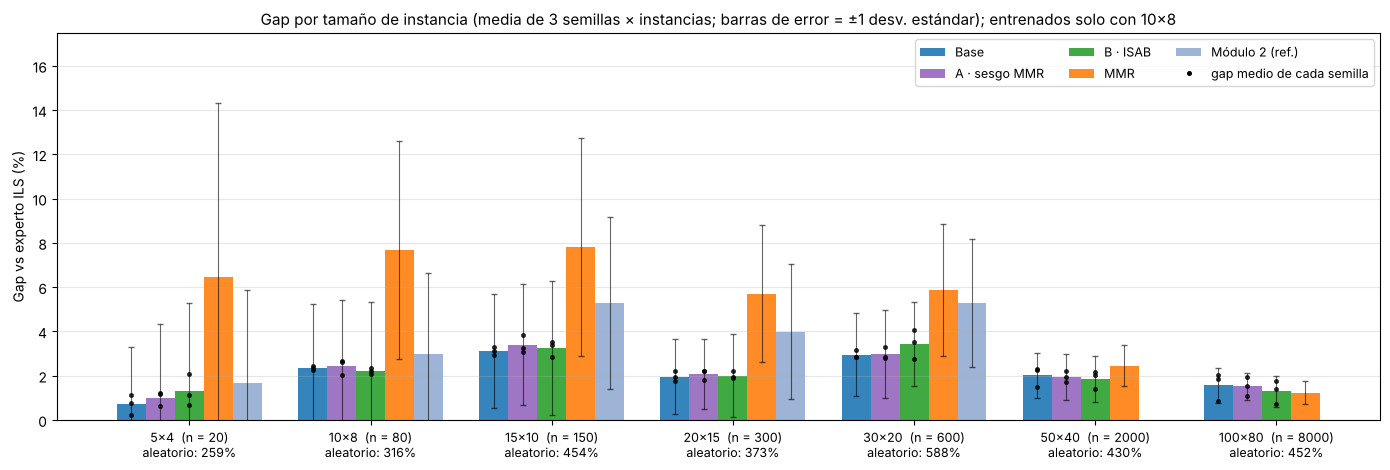

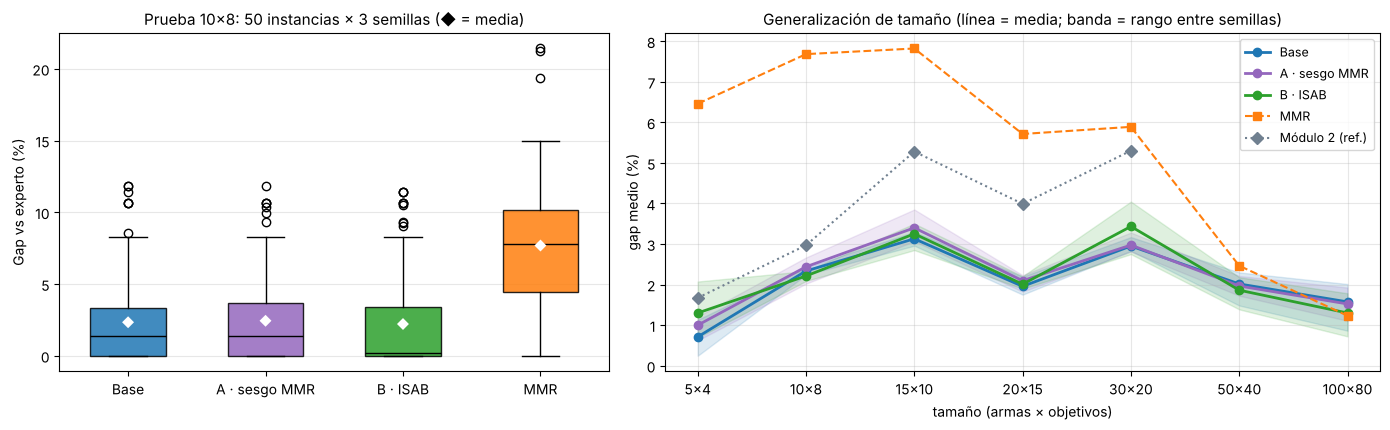

In [18]:
labels = list(EVAL)
fig, ax = plt.subplots(figsize=(14, 4.8))
series = list(MODELOS) + ["MMR"]
width = 0.8 / (len(series) + 1)
x = np.arange(len(labels))
for k, name in enumerate(series):
    means = [EVAL[l][name].mean() for l in labels]; stds = [EVAL[l][name].std() for l in labels]
    xs = x + (k - len(series) / 2) * width
    ax.bar(xs, means, width, yerr=stds, capsize=2.5, color=COLORES[name],
           label=name, alpha=0.9, error_kw=dict(lw=0.8, alpha=0.6))
    if name in MODELOS:                                # gap medio de cada semilla
        for xk, l in zip(xs, labels):
            ax.plot([xk] * len(EVAL_SEEDS[l][name]), [g.mean() for g in EVAL_SEEDS[l][name]], "o", color="black",
                    ms=2.6, alpha=0.75, zorder=3)
ref_x = [k for k, l in enumerate(labels) if l in REF_MODULO2]
ax.bar(np.array(ref_x) + (len(series) / 2) * width, [REF_MODULO2[labels[k]][0] for k in ref_x], width,
       yerr=[REF_MODULO2[labels[k]][1] for k in ref_x], capsize=2.5, color=COLORES["Módulo 2"], label="Módulo 2 (ref.)",
       error_kw=dict(lw=0.8, alpha=0.6))
ax.plot([], [], "o", color="black", ms=2.6, label="gap medio de cada semilla")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks(x)
ax.set_xticklabels([f"{l}  (n = {int(l.split('×')[0]) * int(l.split('×')[1])})\naleatorio: {EVAL[l]['Aleatorio'].mean():.0f}%"
                    for l in labels], fontsize=9)
top = max(EVAL[l][n].mean() + EVAL[l][n].std() for l in labels for n in series)
ax.set_ylabel("Gap vs experto ILS (%)")
ax.set_ylim(min(0, min(EVAL[l][n].mean() for l in labels for n in series) - 0.5), top * 1.22)
ax.set_title(f"Gap por tamaño de instancia (media de {N_SEEDS} semillas × instancias; barras de error = ±1 desv. estándar); "
             "entrenados solo con 10×8", fontsize=11)
hs_, ls_ = ax.get_legend_handles_labels()
order = [k for k, t in enumerate(ls_) if t != "gap medio de cada semilla"] + [ls_.index("gap medio de cada semilla")]
ax.legend([hs_[k] for k in order], [ls_[k] for k in order], ncol=3, fontsize=9, loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); guardar(fig, "tamanos"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
data = [EVAL["10×8"][c] for c in series]
bp = axes[0].boxplot(data, tick_labels=series, patch_artist=True, widths=0.55, medianprops=dict(color="black"))
for patch, name in zip(bp["boxes"], series):
    patch.set_facecolor(COLORES[name]); patch.set_alpha(0.85)
for k, g in enumerate(data, start=1):
    axes[0].text(k, g.mean(), "◆", ha="center", va="center", color="white", fontsize=9)
axes[0].set_ylabel("Gap vs experto (%)")
axes[0].set_title(f"Prueba 10×8: 50 instancias × {N_SEEDS} semillas (◆ = media)", fontsize=11)
axes[0].grid(axis="y", alpha=0.3)
for name in MODELOS:
    seed_means = np.array([[g.mean() for g in EVAL_SEEDS[l][name]] for l in labels])     # (tamaños, semillas)
    axes[1].plot(x, [EVAL[l][name].mean() for l in labels], "o-", color=COLORES[name], label=name, lw=2)
    if seed_means.shape[1] > 1:
        axes[1].fill_between(x, seed_means.min(1), seed_means.max(1), color=COLORES[name], alpha=0.15)
axes[1].plot(x, [EVAL[l]["MMR"].mean() for l in labels], "s--", color=COLORES["MMR"], label="MMR")
axes[1].plot(ref_x, [REF_MODULO2[labels[k]][0] for k in ref_x], "D:", color="slategray", label="Módulo 2 (ref.)")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels); axes[1].set_xlabel("tamaño (armas × objetivos)")
axes[1].set_ylabel("gap medio (%)")
axes[1].set_title("Generalización de tamaño (línea = media; banda = rango entre semillas)", fontsize=11)
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout(); guardar(fig, "comparacion"); plt.show()

**Análisis de la evaluación.** Cada arquitectura se evalúa con sus 3 modelos entrenados (uno por semilla) en las mismas instancias del proyecto del módulo 2.

- **Tamaño de entrenamiento (10×8).** Los tres modelos superan a MMR por más de 5 pp (2,21–2,44 % vs 7,68 %) y al modelo del módulo 2 (2,97 %), que además recibía features heurísticas. Sus medias son muy parecidas: la diferencia máxima (0,23 pp) es menor que la variación entre semillas de una misma arquitectura (hasta 0,65 pp en A). La distribución sí cambia: B iguala al experto en el 42 % de las ejecuciones (base 32 %, A 31 %), su mediana es 0,19 % (base 1,41 %, A 1,35 %) y pierde contra MMR solo en el 3 % (base 7 %, A 10 %). Su media no mejora porque, cuando se equivoca, lo hace por montos parecidos a los de los otros modelos.
- **Generalización de tamaño.** Entrenados solo con 10×8, los tres modelos se mantienen entre 0,7 % y 3,4 % hasta 30×20, mientras MMR queda entre 5,7 % y 7,8 %. Mejoran al módulo 2 en todos los tamaños compartidos: por 0,4–1,0 pp en 5×4 y 10×8, y por 1,9–2,4 pp en 15×10, 20×15 y 30×20, donde el modelo anterior se degradaba más.
- **Instancias grandes.** En 50×40 y 100×80, MMR mejora mucho (2,46 % y 1,23 %) y la referencia se debilita: un ILS de 2 000 iteraciones mejora al de referencia en ≈ 1 %. Los 9 modelos superan a MMR en 50×40, pero en 100×80 MMR queda mejor que la media de las tres arquitecturas (1,30–1,57 %) y solo 3 de los 9 modelos lo superan (uno por arquitectura). Medido contra el ILS largo, el orden no cambia.
- **Diferencias entre arquitecturas.** En cada tamaño las medias difieren en a lo más 0,6 pp, del mismo orden que la variación entre semillas (desviación de 0,1 a 0,6 pp), así que ninguna arquitectura domina. La base es la mejor en 4 de los 7 tamaños (5×4, 15×10, 20×15 y 30×20) y B en los otros 3 (10×8, 50×40 y 100×80; en 100×80 gana a MMR en el 52 % de las ejecuciones, contra 34–36 % de la base y A). A queda a ±0,3 pp de la base en todos los tamaños. B es la más sensible a la semilla en 5×4 y 30×20 (rangos 0,69–2,07 % y 2,75–4,05 %).
- **Tiempo de inferencia.** En 10×8 los modelos resuelven una instancia en 0,3–0,8 ms, entre 11 y 28 veces más rápido que el ILS (9,0 ms). Pero el rollout son W pasos de costo O(n·d): en 100×80 tarda 113–116 ms con la base y A, y 1,1 s con B, más que el ILS de 100 iteraciones (40 ms).

## 10. Discusión y conclusiones

1. **Responsabilidades separadas.** El rediseño cumple la definición de la tarea: el encoder solo ve $V_j$ y $p_{ij}$ (token aprendible para las armas y la matriz como aristas) y corre una vez por instancia; el estado entra solo al decoder. Sin las features heurísticas del módulo 2, la base supera a MMR desde la primera época y mejora al módulo 2 en los 5 tamaños compartidos (2,33 % vs 2,97 % en 10×8; 1,96–3,13 % vs 3,99–5,30 % entre 15×10 y 30×20).
2. **Complejidad.** El encoder es lineal en n = W·T (atención bipartita) y se paga una vez; el decoder es lineal por paso (pendiente medida 1,06 vs 2,11 del módulo 2), así que una instancia 50×40 se resuelve 36 veces más rápido que con el modelo anterior. La interacción entre pares de la variante B sería cuadrática (pendiente 2,22) y con ISAB queda lineal (pendiente 1,20, o 1,02 sin el tamaño más grande). El límite que queda es el número de pasos: W pasos de O(n·d) por instancia, que en 100×80 ya es más lento que el ILS.
3. **Sesgo inductivo (A).** Con la ganancia de MMR como sesgo, el modelo parte desde MMR (6,9 % en vez de 821 %), llega un poco antes a los umbrales (gap < 3 % en 9–12 épocas vs 10–13) y los α aprendidos crecen, así que el modelo sí usa el criterio. Pero la base aprende lo mismo en una época y la calidad final es equivalente (diferencias ≤ 0,3 pp, dentro de la variación entre semillas): en este problema el sesgo acelera el inicio, pero no cambia el resultado final.
4. **Atención eficiente (B).** Que los pares interactúen con ISAB da la menor pérdida, la mayor accuracy y más soluciones exactas (42 % iguales al experto en 10×8, solo 3 % de derrotas contra MMR), pero no un menor gap medio, y cuesta 4 veces más por época y hasta 10 veces más en inferencia.
5. **Recomendación.** Con estos datos, la base es la mejor relación calidad/costo; A conviene si el presupuesto de entrenamiento es muy corto (parte desde MMR) y B si importa resolver exactamente más instancias. Como trabajo futuro, entrenar con varios tamaños (en 50×40 y 100×80 MMR se acerca) y combinar A y B.

In [19]:
summary = {
    "diagnostico_modulo2": DIAGNOSTICO,
    "criterio_mmr": CRITERIO_MMR,
    "params": {name: n_params(WTAPModel(v)) for name, v in MODELOS.items()},
    "train_cfg": TRAIN_CFG, "n_seeds": N_SEEDS, "n_train": N_TRAIN,
    "n_train_decisions": int(D_train["Y"].numel()), "n_val_decisions": int(D_val["Y"].numel()),
    "timing": {name: {k: [float(x) for x in v] for k, v in t.items()} for name, t in TIMES.items()},
    "slopes_step": SLOPES, "slopes_encoder": SLOPES_ENC, "slopes_total": SLOPES_TOTAL, "speedup_vs_mod2": SPEEDUP,
    "histories": {name: [{k: H[k] for k in ("train_loss", "val_loss", "train_acc", "val_acc", "val_gap", "alpha",
                                             "lr", "time", "best_epoch", "epochs", "init")} for _, H in RUNS[name]]
                  for name in MODELOS},
    "alpha_enc": RUNS["A · sesgo MMR"][0][1].get("alpha_enc") if "A · sesgo MMR" in RUNS else None,
    "convergence": CONV,
    "eval": {label: {n: {"mean": float(g.mean()), "std": float(g.std()), "median": float(np.median(g)),
                         "pct_optimal": float(100 * np.mean(g < 1e-6)),
                         "wins_vs_mmr": float(vs_mmr(label, n)[0]), "ties_vs_mmr": float(vs_mmr(label, n)[1]),
                         "n": int(len(g)), "n_instances": int(len(EVAL_SEEDS[label][n][0])),
                         "seed_means": [float(s.mean()) for s in EVAL_SEEDS[label][n]],
                         "seed_std": float(np.std([s.mean() for s in EVAL_SEEDS[label][n]]))}
                     for n, g in d.items()} for label, d in EVAL.items()},
    "eval_time_ms": EVAL_TIME,
    "ref_modulo2": REF_MODULO2, "ref_ils_largo": REF_LARGA,
}
with open("figuras_t6/resultados.json", "w") as f:
    json.dump(summary, f, indent=1, ensure_ascii=False, default=float)
print("Resultados guardados en figuras_t6/resultados.json")
# pesos de los 9 modelos entrenados (~7 MB), por si se quiere re-evaluar sin re-entrenar
torch.save({name: [m.state_dict() for m, _ in RUNS[name]] for name in MODELOS}, "modelos_t6.pt")
print("Pesos guardados en modelos_t6.pt")

Resultados guardados en figuras_t6/resultados.json
Pesos guardados en modelos_t6.pt
